# PINZAS 4 — Barrido de potencia con la partícula atrapada

Dos grabaciones del 12/11/2026 con una partícula en la trampa y la platina quieta, bajando la potencia del láser en ocho escalones de 30 s: `LASER 5` (30, 25, 20, 15, 7, < 7, < 7, 0 mW) y `BARRIDO POTENCIAS 2` (30, 25, 20–23, 15, 7, 3, < 3, ≪ 3 mW).

**Qué se espera.** La trampa es un pozo de potencial; cerca del centro la fuerza es $-\kappa x$ y la rigidez $\kappa$ crece con la potencia. La partícula está sobreamortiguada: **no oscila**. Lo que depende de la potencia es el tiempo que tarda en volver al centro, $\tau_c = \gamma/\kappa$, o la frecuencia de esquina del espectro, $f_c = \kappa/(2\pi\gamma)$, con $\gamma$ el arrastre viscoso. El tamaño de las fluctuaciones da $\kappa$ sin conocer $\gamma$: $\langle x^2\rangle = k_BT/\kappa$.

**Qué hace este notebook.**

1. Línea de tiempo real de la potencia y tramo usable de cada escalón.
2. Posición de la partícula: el láser ensucia el canal verde y hubo que medirla de nuevo. Ruido de localización.
3. Radio, flujo del líquido y arrastre $\gamma$ medido con la misma partícula.
4. Validación de los estimadores con datos sintéticos.
5. $\kappa$ por escalón y por eje con cinco estimadores; forma del pozo; $\tau_c$ y $f_c$.
6. $\kappa$ contra potencia; $\gamma = \kappa\,\tau_c$; cuánto pesa la exposición desconocida.
7. Potencia baja: cuándo deja de estar atrapada.

Entradas: `datos/<grabación>/atrapada.csv`, `trayectorias.csv`, el cuaderno (`datos/cuaderno/potencias_cuaderno.csv`) y, la primera vez, los TIFF originales. Funciones en `analisis/potencia.py`. Salidas: `datos/pinzas/potencia_*.csv` (ver `datos/pinzas/LEEME potencia.txt`) y `figuras/PINZAS 4/`. Dudas y supuestos: `analisis/DUDAS potencia.md`.

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter
import potencia as po
from pinzas_datos import RAIZ, DATOS, ESCALA_UM
from pinzas import fisica

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_rows", 200)

# estilo de ESTILO_FIGURAS.md (raíz del repo)
plt.style.use("seaborn-v0_8")
fs = 14
plt.rcParams.update({"font.family": "serif", "font.size": fs, "axes.labelsize": fs,
                     "xtick.labelsize": fs, "ytick.labelsize": fs, "legend.fontsize": fs,
                     "mathtext.default": "regular", "mathtext.fontset": "cm", "legend.frameon": True})
SERIE1, SERIE2, AJUSTE, AZUL = "#2A9D8F", "#E76F51", "#264653", "#4C72B0"
COLOR = {"LASER 5": SERIE1, "BARRIDO POTENCIAS 2": SERIE2}
MARCA = {"LASER 5": "D", "BARRIDO POTENCIAS 2": "o"}
FIGURAS = os.path.join(RAIZ, "figuras", "PINZAS 4")
SALIDA = po.SALIDA
os.makedirs(FIGURAS, exist_ok=True); os.makedirs(SALIDA, exist_ok=True)
EB = dict(ms=7, capsize=3, elinewidth=1.6, capthick=1.6, mew=1.6, zorder=3)
LEY = dict(fontsize=12, facecolor="white", framealpha=0.9)


def guardar(fig, nombre):
    fig.tight_layout()
    fig.savefig(os.path.join(FIGURAS, nombre + ".pdf"), bbox_inches="tight")
    fig.savefig(os.path.join(FIGURAS, nombre + ".png"), bbox_inches="tight", dpi=300)


def csv(tabla, nombre):
    tabla.to_csv(os.path.join(SALIDA, nombre), index=False, float_format="%.5g")


T = 296.15            # K: 23 °C SUPUESTO (no se anotó); ± 3 °C cambia kT en ± 1 %
kT = po.KT_PN_UM(T)   # pN·µm
print("kT = %.3e pN·µm a %.0f °C" % (kT, T - 273.15))

kT = 4.089e-03 pN·µm a 23 °C


## 1. Los datos: una tabla por cuadro

`po.tabla_cuadros()` lee `datos/pinzas/potencia_cuadros.csv` si existe. Si no, relee los TIFF originales alrededor del láser (unos minutos) y mide en cada cuadro la luz roja del láser y la posición de la partícula con varios estimadores (sección 3). Las columnas están explicadas en `datos/pinzas/LEEME potencia.txt`.

In [2]:
cu, ru = po.tabla_cuadros()
esc = po.escalones()
for g in po.BARRIDOS:
    d = cu[cu.grabacion == g]
    print("%-20s %d cuadros, %.1f s, %.3f cuadros/s, período %.1f ms | partícula medida en %d cuadros"
          % (g, len(d), d.t_s.max(), 1 / d.t_s.diff().median(), 1e3 * d.t_s.diff().median(), d.xc_um.notna().sum()))
esc[["grabacion", "n", "potencia_texto", "t_ini_s", "t_fin_s", "t_cambio_s", "t_ini_usado_s", "t_fin_usado_s"]]

LASER 5              3165 cuadros, 241.0 s, 13.158 cuadros/s, período 76.0 ms | partícula medida en 2760 cuadros
BARRIDO POTENCIAS 2  3006 cuadros, 240.4 s, 12.500 cuadros/s, período 80.0 ms | partícula medida en 2575 cuadros


,grabacion,n,potencia_texto,t_ini_s,t_fin_s,t_cambio_s,t_ini_usado_s,t_fin_usado_s
0,LASER 5,1,30 mW (máxima),0,30,0.0,5.0,30.5
1,LASER 5,2,25 mW,30,60,31.5,35.0,60.5
2,LASER 5,3,20 mW,60,90,61.5,65.0,90.5
3,LASER 5,4,15 mW,90,120,91.5,95.0,120.5
4,LASER 5,5,7 mW,120,150,121.5,125.0,150.5
5,LASER 5,6,< 7 mW,150,180,151.5,155.0,180.5
6,LASER 5,7,< 7 mW,180,210,181.5,185.0,210.5
7,LASER 5,8,0,210,240,211.5,215.0,240.5
8,BARRIDO POTENCIAS 2,1,30 mW (máxima),0,30,0.0,5.0,30.5
9,BARRIDO POTENCIAS 2,2,25 mW,30,60,31.5,35.0,60.5


## 2. Línea de tiempo de la potencia

La partícula atrapada dispersa el láser y en la cámara se ve una mancha roja. Tres indicadores por cuadro, los tres medidos sobre los píxeles crudos y referidos al valor con el láser apagado:

- `rojo_nucleo`: rojo en un disco de 6 px en el láser, relativo al rojo de la iluminación;
- `rojo_halo`: lo mismo en un anillo de 25 a 50 px, donde el láser agrega **pocas cuentas** (no puede saturar);
- `rojo_lejos`: cociente rojo/verde a más de 100 px del láser, en una ventana de 221 px (luz del láser desparramada).

In [3]:
filas = []
for g in po.BARRIDOS:
    d = cu[cu.grabacion == g]
    ref = d[(d.t_s >= 5) & (d.t_s < 30.5)]
    for _, e in esc[esc.grabacion == g].iterrows():
        m = d[(d.t_s >= e.t_ini_usado_s) & (d.t_s < e.t_fin_usado_s)]
        filas.append(dict(grabacion=g, escalon=int(e.n), cuaderno=e.potencia_texto,
                          rojo_max_cuentas=m.rojo_max.mean(),
                          nucleo_rel=m.rojo_nucleo.mean() / ref.rojo_nucleo.mean(),
                          halo_rel=m.rojo_halo.mean() / ref.rojo_halo.mean(),
                          lejos_rel=m.rojo_lejos.mean() / ref.rojo_lejos.mean(),
                          distancia_um=np.hypot(m.xc_um, m.yc_um).mean(),
                          cuadros_con_particula=int(m.xc_um.notna().sum()), cuadros=len(m)))
rojo = pd.DataFrame(filas)
csv(rojo, "potencia_rojo_por_escalon.csv")
rojo.round(3)

,grabacion,escalon,cuaderno,rojo_max_cuentas,nucleo_rel,halo_rel,lejos_rel,distancia_um,cuadros_con_particula,cuadros
0,LASER 5,1,30 mW (máxima),116.991,1.000,1.000,1.000,0.128,335,335
1,LASER 5,2,25 mW,116.352,0.974,1.043,0.901,0.130,335,335
2,LASER 5,3,20 mW,124.904,1.003,1.020,0.952,0.129,335,335
3,LASER 5,4,15 mW,120.566,0.988,0.923,1.033,0.179,334,334
4,LASER 5,5,7 mW,134.636,1.049,0.924,1.049,0.281,335,335
5,LASER 5,6,< 7 mW,37.143,0.072,0.042,0.323,3.203,204,335
6,LASER 5,7,< 7 mW,31.066,-0.009,-0.124,-0.013,3.128,163,335
7,LASER 5,8,0,30.060,-0.036,-0.285,-0.032,2.518,299,335
8,BARRIDO POTENCIAS 2,1,30 mW (máxima),135.824,1.000,1.000,1.000,0.090,319,319
9,BARRIDO POTENCIAS 2,2,25 mW,132.389,0.967,1.048,0.958,0.092,319,319


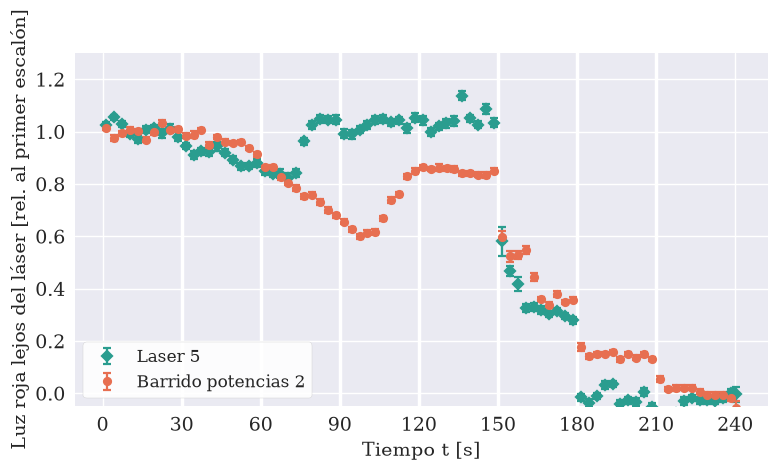

In [4]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for g in po.BARRIDOS:
    d = cu[cu.grabacion == g]
    ref = d[(d.t_s >= 5) & (d.t_s < 30.5)].rojo_lejos.mean()
    b = d.groupby((d.t_s // 3).astype(int))
    t, y, ey = b.t_s.mean(), b.rojo_lejos.mean() / ref, b.rojo_lejos.std() / np.sqrt(b.size()) / ref
    ax.errorbar(t, y, yerr=ey, fmt=MARCA[g], color=COLOR[g], mfc=COLOR[g], mec=COLOR[g],
                **{**EB, "ms": 5}, label=g.capitalize() if g != "LASER 5" else "Laser 5")
for tt in range(30, 240, 30):
    ax.axvline(tt, color="white", lw=2.5, zorder=1)
ax.set_xlabel(r"Tiempo $t$ [s]"); ax.set_ylabel("Luz roja lejos del láser [rel. al primer escalón]")
ax.set_xticks(range(0, 241, 30)); ax.set_ylim(-0.05, 1.3)
ax.legend(loc="lower left", **LEY)
guardar(fig, "rojo_tiempo")

LASER 5 | el rojo lejano cruza hacia abajo: 85 % a los 151.1 s, 50 % a los 151.3 s, 10 % a los 180.4 s
BARRIDO POTENCIAS 2 | el rojo lejano cruza hacia abajo: 85 % a los 150.9 s, 50 % a los 155.7 s, 10 % a los 184.2 s


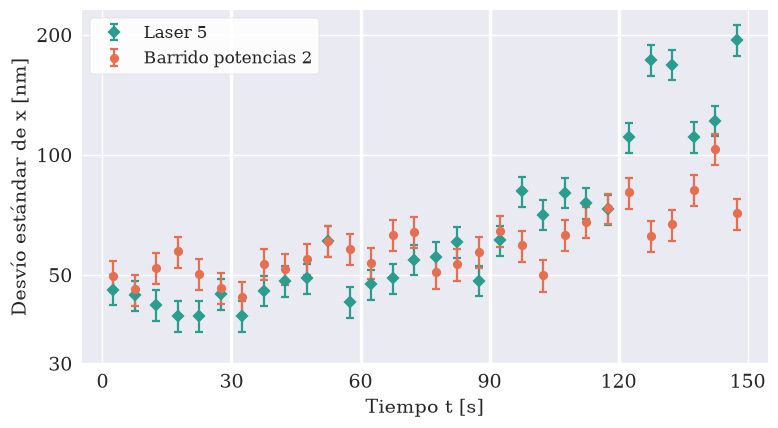

In [5]:
# dispersión de la posición en ventanas de 5 s (sin la recta de cada ventana)
fig, ax = plt.subplots(figsize=(8, 4.5))
for g in po.BARRIDOS:
    d = cu[(cu.grabacion == g) & cu.xc_um.notna() & (cu.t_s < 150)]
    ts, ss, es = [], [], []
    for k, v in d.groupby((d.t_s // 5).astype(int)):
        if len(v) < 40:
            continue
        r = po.quitar_tendencia(v.t_s.values, v.xc_um.values, 1)
        ts.append(v.t_s.mean()); ss.append(1e3 * r.std()); es.append(1e3 * r.std() / np.sqrt(2 * len(r)))
    ax.errorbar(ts, ss, yerr=es, fmt=MARCA[g], color=COLOR[g], mfc=COLOR[g], mec=COLOR[g],
                **{**EB, "ms": 5}, label="Laser 5" if g == "LASER 5" else "Barrido potencias 2")
for tt in range(30, 150, 30):
    ax.axvline(tt, color="white", lw=2.5, zorder=1)
ax.set_yscale("log"); ax.set_yticks([30, 50, 100, 200]); ax.set_yticklabels(["30", "50", "100", "200"])
ax.yaxis.set_minor_formatter(NullFormatter())
ax.set_xlabel(r"Tiempo $t$ [s]"); ax.set_ylabel(r"Desvío estándar de $x$ [nm]"); ax.set_xticks(range(0, 151, 30))
ax.legend(loc="upper left", **LEY)
guardar(fig, "desvio_tiempo")

# cuándo cae el rojo: primer cuadro en que rojo_lejos baja del 85 %, 50 % y 10 % de su valor entre 125 y 148 s
for g in po.BARRIDOS:
    d = cu[cu.grabacion == g]
    ref = d[(d.t_s >= 125) & (d.t_s < 148)].rojo_lejos.mean()
    s = (d.rojo_lejos.rolling(7, center=True).median() / ref).values
    print(g, "| el rojo lejano cruza hacia abajo:",
          ", ".join("%.0f %% a los %.1f s" % (100 * u, d.t_s.values[np.flatnonzero((s < u) & (d.t_s.values > 140))[0]]) for u in (0.85, 0.5, 0.1)))

**Qué se ve.**

- **De 0 a 150 s el rojo no sigue a la potencia.** Según el cuaderno baja de 30 a 7 mW (a menos de la cuarta parte); el rojo del núcleo se queda igual (dentro de 5 % en `LASER 5` y de 12 % en `BARRIDO POTENCIAS 2`). El halo y la luz lejana cambian hasta ± 25–30 %, pero de a poco y sin escalones a los 30, 60, 90 y 120 s (probablemente otras partículas que cruzan la zona donde se mide). **No es saturación de los píxeles**: el máximo del rojo es de 110 a 230 cuentas sobre 255 y cambia de un cuadro a otro, y el halo y la luz lejana valen pocas cuentas. La luz roja que llega a la cámara **no es proporcional a la potencia** en ese rango, así que **no sirve para verificar los escalones de 30 a 7 mW ni para ponerle un valor a los "< 7 mW"**. Una explicación posible, no verificada: delante de la cámara hay un filtro que bloquea la línea del láser, y lo que pasa es la emisión espontánea del diodo, que por encima del umbral casi no depende de la corriente.
- Que la potencia sí cambia en esos 150 s lo dice la partícula: el desvío estándar de la posición crece escalón a escalón (figura `desvio_tiempo`).
- Por debajo de 7 mW el rojo **sí cae, en escalones**: a los 151–152 s, 181 s y 211 s. O sea, **cada cambio de potencia ocurre unos 1.5 s después del múltiplo de 30 s** del cuaderno. En `LASER 5` desde los 181 s no queda nada de rojo: el láser ya está apagado (o invisible) en el escalón 7, que el cuaderno anota como "< 7 mW".
- Desde el cambio de los 151 s la partícula se aleja varias micras (columna `distancia_um`): **solo los escalones 1 a 5 (30 a 7 mW) son de partícula atrapada**.

**Tramo usable de cada escalón:** desde 5 s después del múltiplo de 30 s (3.5 s después del cambio real) hasta 0.5 s después del múltiplo siguiente (1 s antes del cambio): 25.5 s, unos 320–335 cuadros. Los cambios de los 30, 60, 90 y 120 s no se ven en el rojo; se supone el mismo retraso de 1.5 s.

## 3. La posición de la partícula y el ruido de localización

**El láser ensucia el canal verde.** La cámara entrega RGB ya procesado, y el procesado **resta** una fracción del rojo a los otros canales. Donde está la mancha del láser el verde baja: en el centro de la partícula atrapada aparece un punto oscuro que **no es la partícula**. La conversión a CSV localiza por simetría radial sobre el verde y usa también ese punto, que no se mueve como la partícula.

El cruce se mide en cada grabación con la regresión temporal, píxel por píxel, del verde contra el rojo en el núcleo del láser (`c_G`). La posición se vuelve a medir sobre **verde + c_G·(rojo − rojo del fondo)**, dividido por el fondo (mediana de los cuadros con la trampa vacía), y **sin usar los píxeles a menos de 8 px del láser** (estimador `c`). Otros tres estimadores sirven de control: `u` (corregido, sin tapar), `s` (verde tal cual, sin tapar: réplica de la conversión) y `b` (canal azul).

                                               radio_aparente_um  desvio_entre_cuadros_um  cuadros
grabacion           que                                                                           
BARRIDO POTENCIAS 2 atrapada, verde corregido              1.819                    0.024       63
                    atrapada, verde tal cual               1.844                    0.029       63
                    suelta                                 1.777                    0.059       55
LASER 5             atrapada, verde corregido              1.779                    0.018       67
                    atrapada, verde tal cual               1.794                    0.020       67
                    suelta                                 1.824                    0.073       38
cruce del rojo al verde, c_G: {'LASER 5': 0.295, 'BARRIDO POTENCIAS 2': 0.139}


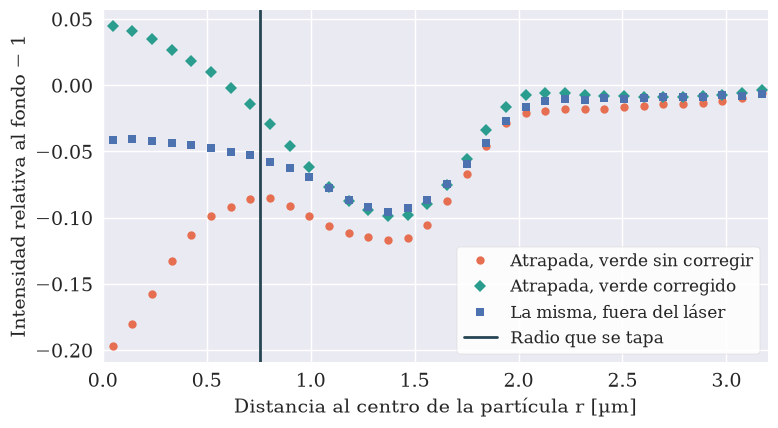

In [6]:
# perfil radial de la partícula: verde tal cual, verde corregido y la misma partícula ya suelta
ruta = os.path.join(SALIDA, "potencia_perfiles.csv")
if os.path.exists(ruta):
    perf = pd.read_csv(ruta)
else:
    filas = []
    for g in po.BARRIDOS:
        d = cu[cu.grabacion == g]
        a = pd.read_csv(os.path.join(DATOS, g, "atrapada.csv"))
        x0, y0 = a.x0_px.values[0], a.y0_px.values[0]
        cG = float(ru[ru.grabacion == g].c_G.dropna().iloc[0])
        for que, (ta, tb), corr in (("atrapada, verde tal cual", (5, 30.5), False), ("atrapada, verde corregido", (5, 30.5), True),
                                    ("suelta", (156, 178), False)):
            m = (d.t_s >= ta) & (d.t_s < tb) & d.xc_um.notna()
            rb, sd, rm, prof, p = po.radio_aparente(g, d.cuadro.values[m][::5], d.xc_um.values[m][::5] / ESCALA_UM + x0,
                                                    d.yc_um.values[m][::5] / ESCALA_UM + y0, corr, cG)
            for i, v in enumerate(p):
                filas.append(dict(grabacion=g, que=que, r_um=(i + 0.5) * ESCALA_UM, perfil=v, radio_aparente_um=rb * ESCALA_UM,
                                  desvio_entre_cuadros_um=sd * ESCALA_UM, cuadros=int(m.sum() // 5)))
    perf = pd.DataFrame(filas)
    csv(perf, "potencia_perfiles.csv")

fig, ax = plt.subplots(figsize=(8, 4.5))
d = perf[perf.grabacion == "LASER 5"]
for que, c, mk, lab in (("atrapada, verde tal cual", SERIE2, "o", "Atrapada, verde sin corregir"),
                        ("atrapada, verde corregido", SERIE1, "D", "Atrapada, verde corregido"),
                        ("suelta", AZUL, "s", "La misma, fuera del láser")):
    v = d[d.que == que]
    ax.plot(v.r_um, v.perfil, mk, ms=6, color=c, mec=c, mfc=c, zorder=3, label=lab)
ax.axvline(8 * ESCALA_UM, color=AJUSTE, lw=2, zorder=2, label="Radio que se tapa")
ax.set_xlabel(r"Distancia al centro de la partícula $r$ [µm]"); ax.set_ylabel("Intensidad relativa al fondo − 1")
ax.set_xlim(0, 3.2); ax.legend(loc="lower right", **LEY)
guardar(fig, "perfil_radial")
print(perf.groupby(["grabacion", "que"])[["radio_aparente_um", "desvio_entre_cuadros_um", "cuadros"]].first().round(3))
print("cruce del rojo al verde, c_G:", {g: round(float(ru[ru.grabacion == g].c_G.dropna().iloc[0]), 3) for g in po.BARRIDOS})

In [7]:
# desvío estándar por escalón con cada estimador (sin la tendencia lenta), en nm
filas = []
for g in po.BARRIDOS:
    d = cu[cu.grabacion == g]
    for _, e in esc[(esc.grabacion == g) & (esc.n <= po.N_ATRAPADA)].iterrows():
        m = (d.t_s >= e.t_ini_usado_s) & (d.t_s < e.t_fin_usado_s)
        f = dict(grabacion=g, escalon=int(e.n), potencia_mW=e.potencia_mW)
        for eje in "xy":
            for q, nom in (("_conv", "conversion"), ("s", "replica"), ("u", "corregido"), ("c", "corregido_tapado")):
                f["sd_%s_%s_nm" % (eje, nom)] = 1e3 * po.quitar_tendencia(d.t_s.values[m], d["%s%s_um" % (eje, q)].values[m]).std()
        filas.append(f)
est = pd.DataFrame(filas)
csv(est, "potencia_estimadores_de_posicion.csv")
# con la partícula fuera del láser (después de los 155 s): pendiente de cada estimador contra el que se usa
for g in po.BARRIDOS:
    d = cu[(cu.grabacion == g) & (cu.t_s > 155) & cu.xc_um.notna() & cu.x_conv_um.notna()]
    d = d[d.particula == d.particula.iloc[0]]
    print("%-20s fuera del láser (%d cuadros): pendiente contra 'corregido_tapado' -> corregido: %.3f (x) %.3f (y) | conversión: %.3f (x) %.3f (y)"
          % (g, len(d), np.polyfit(d.xc_um, d.xu_um, 1)[0], np.polyfit(d.yc_um, d.yu_um, 1)[0],
             np.polyfit(d.xc_um, d.x_conv_um, 1)[0], np.polyfit(d.yc_um, d.y_conv_um, 1)[0]))
est.round(1)

LASER 5              fuera del láser (204 cuadros): pendiente contra 'corregido_tapado' -> corregido: 1.007 (x) 0.991 (y) | conversión: 0.953 (x) 1.009 (y)
BARRIDO POTENCIAS 2  fuera del láser (637 cuadros): pendiente contra 'corregido_tapado' -> corregido: 0.988 (x) 1.003 (y) | conversión: 0.999 (x) 1.030 (y)


,grabacion,escalon,potencia_mW,sd_x_conversion_nm,sd_x_replica_nm,sd_x_corregido_nm,sd_x_corregido_tapado_nm,sd_y_conversion_nm,sd_y_replica_nm,sd_y_corregido_nm,sd_y_corregido_tapado_nm
0,LASER 5,1,30.0,42.8,47.0,37.9,43.0,57.8,57.4,42.7,45.5
1,LASER 5,2,25.0,44.2,51.1,43.6,50.8,65.0,64.4,50.7,55.4
2,LASER 5,3,20.0,61.5,60.9,48.5,56.9,72.9,71.7,57.0,65.0
3,LASER 5,4,15.0,75.0,76.2,71.2,79.9,97.6,100.5,75.5,87.8
4,LASER 5,5,7.0,157.1,160.1,165.6,173.1,159.7,162.9,116.2,129.6
5,BARRIDO POTENCIAS 2,1,30.0,32.8,34.5,50.3,53.0,44.7,48.1,48.5,53.6
6,BARRIDO POTENCIAS 2,2,25.0,35.9,36.9,53.4,57.1,41.3,44.4,45.0,50.9
7,BARRIDO POTENCIAS 2,3,21.5,38.8,39.3,55.1,60.0,47.2,50.2,50.1,55.5
8,BARRIDO POTENCIAS 2,4,15.0,38.3,39.2,60.9,65.7,54.5,59.7,52.4,61.9
9,BARRIDO POTENCIAS 2,5,7.0,51.2,54.2,79.6,84.0,85.2,90.0,73.6,84.8


La réplica (`replica`) reproduce la conversión a CSV (`conversion`). Con el láser corregido la dispersión cambia, y **en sentidos distintos según la grabación y el eje**: en `BARRIDO POTENCIAS 2` la dispersión en $x$ **sube** 45–65 % (el punto oscuro estaba fijo y tiraba la posición medida hacia el láser) y en `LASER 5` la de $y$ **baja** 10–20 % (ahí la mancha se mueve más que la partícula). Como $\kappa \propto 1/\sigma^2$, con las posiciones de `atrapada.csv` la rigidez saldría hasta 2–3 veces distinta. Tapar o no el núcleo después de corregir cambia $\sigma$ menos de 15 %. Con la partícula fuera del láser (después de los 155 s) los estimadores coinciden: las pendientes entre ellos están impresas arriba.

En `LASER 5` el perfil corregido queda más claro en el centro que el de la partícula suelta (figura): la corrección no es perfecta, o la partícula atrapada está a otra altura y enfoca distinto. Por eso además se tapa el núcleo.

**De acá en adelante se usa el estimador `c`** (`xc_um`, `yc_um`).

### Ruido de localización

Con 12–13 cuadros por segundo, a potencia alta el movimiento térmico es casi blanco, igual que el ruido: no se separan mirando la serie. El ruido se mide aparte, **en la misma grabación**: a la imagen promedio de la partícula (la plantilla, sin ruido) se le suma el ruido real de la cámara en esos mismos píxeles (diferencia de dos cuadros seguidos con la trampa vacía, dividida por $\sqrt 2$) y se localiza con el mismo estimador. El desvío de esas posiciones es el ruido de localización debido al ruido de píxel.

Chequeo del método con algo que no se mueve: dos manchas de polvo del sensor. Su posición medida cuadro a cuadro tiene un desvío que el método de la plantilla tiene que predecir.

In [8]:
r = ru[ru.escalon > 0][["grabacion", "escalon", "ruido_xc_um", "ruido_yc_um", "ruido_xu_um", "ruido_yu_um"]].copy()
r.iloc[:, 2:] *= 1e3
print("Ruido de píxel por escalón [nm] (c: corregido y tapado; u: corregido sin tapar)")
print(r.round(1).to_string(index=False))
p = ru[ru.escalon == 0][["grabacion", "ruido_xc_um", "ruido_yc_um", "ruido_xu_um", "ruido_yu_um"]].copy()
p.columns = ["grabacion", "medido_x", "medido_y", "plantilla_x", "plantilla_y"]
p.iloc[:, 1:] *= 1e3
p["cociente_x"], p["cociente_y"] = p.plantilla_x / p.medido_x, p.plantilla_y / p.medido_y
print("\nManchas de polvo (quietas): desvío medido y el que predice la plantilla [nm]")
print(p.round(2).to_string(index=False))
RUIDO = {(g, eje): po.ruido_de_referencia(ru, g, eje) for g in po.BARRIDOS for eje in "xy"}
print("\nRuido que se resta (promedio de los escalones 1 y 2):",
      {k: "%.1f nm" % (1e3 * np.sqrt(v)) for k, v in RUIDO.items()})

Ruido de píxel por escalón [nm] (c: corregido y tapado; u: corregido sin tapar)
          grabacion  escalon  ruido_xc_um  ruido_yc_um  ruido_xu_um  ruido_yu_um
            LASER 5        1         22.0         19.2         18.0         16.7
            LASER 5        2         22.1         19.4         17.9         16.5
            LASER 5        3         21.3         20.2         17.1         16.9
            LASER 5        4         21.2         22.2         17.6         18.2
            LASER 5        5         22.5         24.2         19.5         20.4
BARRIDO POTENCIAS 2        1         38.6         31.9         36.3         29.6
BARRIDO POTENCIAS 2        2         40.0         32.0         38.1         28.7
BARRIDO POTENCIAS 2        3         40.4         33.4         38.3         29.9
BARRIDO POTENCIAS 2        4         41.8         33.9         40.6         29.5
BARRIDO POTENCIAS 2        5         42.6         34.8         40.9         29.7

Manchas de polvo (quietas): 

La plantilla predice el desvío de las manchas quietas dentro de ± 15 %. Se toma una incerteza de **± 10 % en el ruido (± 20 % en su varianza)**.

El ruido es de **19–22 nm** en `LASER 5` y de **32–39 nm** en `BARRIDO POTENCIAS 2` (menos luz y, con el láser corregido, queda menos borde para localizar). A 30 mW el desvío total es de 43–54 nm: **el ruido es el 20–26 % de la varianza medida en `LASER 5` y el 36–55 % en `BARRIDO POTENCIAS 2`**.

Es una **cota inferior** del ruido: no incluye lo que agregue la mancha del láser, que cambia de forma de un cuadro a otro. Si el ruido real es mayor, $\kappa$ es mayor que el informado.

## 4. Radio, flujo del líquido y arrastre $\gamma$

**Radio aparente.** Con la definición de `medir_radios.py` (donde el perfil radial, yendo hacia afuera desde el anillo oscuro, recupera la mitad de su profundidad; el mínimo se busca entre 8 y 32 px para no tomar el punto del láser): **1.78–1.84 µm en las dos grabaciones**, atrapada o suelta (tabla de arriba). Es el mismo radio aparente de las partículas de tamaño nominal del browniano (1.8 µm para 1.5 µm nominales). El radio aparente depende del foco y de la difracción: sirve para decir que **las dos son partículas de tamaño nominal**, no como radio absoluto mejor que ~0.3 µm.

**La platina está quieta, el líquido no.** Las partículas libres del campo derivan todas para el mismo lado.

In [9]:
filas = []
for g in po.BARRIDOS:
    fl = po.flujo_libres(g)
    d = cu[cu.grabacion == g]
    dt = d.t_s.diff().median()
    filas.append(dict(grabacion=g, particulas_libres=len(fl), vx_um_s=fl.vx_um_s.median(), vy_um_s=fl.vy_um_s.median(),
                      dispersion_vx=fl.vx_um_s.std(), dispersion_vy=fl.vy_um_s.std(),
                      v_um_s=np.hypot(fl.vx_um_s.median(), fl.vy_um_s.median()),
                      correlacion_imagenes_vx=d.plat_dx_um.mean() / dt, correlacion_imagenes_vy=d.plat_dy_um.mean() / dt))
flujo = pd.DataFrame(filas)
csv(flujo, "potencia_flujo.csv")
flujo.round(3)

,grabacion,particulas_libres,vx_um_s,vy_um_s,dispersion_vx,dispersion_vy,v_um_s,correlacion_imagenes_vx,correlacion_imagenes_vy
0,LASER 5,10,-0.207,0.163,0.048,0.045,0.263,-0.154,0.120
1,BARRIDO POTENCIAS 2,9,-0.158,0.165,0.044,0.041,0.228,-0.097,0.083


Las partículas libres se mueven a **0.23–0.26 µm/s hacia −x, +y** (izquierda y abajo en la imagen), todas parecido (dispersión 0.05 µm/s). La correlación de imágenes de `platina.csv` (columnas `plat_*`) da ese mismo sentido y 0.13–0.20 µm/s; cuadro a cuadro es ruido (± 0.03–0.04 µm): lo que sigue es a las partículas, no a la platina (las manchas de polvo del sensor no se mueven, y partículas pegadas al vidrio no se ven). Con estos datos no se distingue un flujo del líquido de una deriva lenta de la platina; para la partícula atrapada es lo mismo: el líquido pasa a ~0.25 µm/s y la empuja con $\gamma v \approx 0.015$ pN.

**Arrastre $\gamma$ de la misma partícula.** Después de los 152 s la trampa casi no la retiene. La varianza de sus desplazamientos crece como $2D\tau$; con los primeros 4 retardos sale $D$ y de ahí $\gamma = k_BT/D$, sin suponer viscosidad ni radio. Se usa la varianza del desplazamiento dentro de trozos de 6 s (no su media cuadrática), así el flujo no entra.

In [10]:
filas = []
for g, (ta, tb) in (("LASER 5", (153, 178)), ("BARRIDO POTENCIAS 2", (153, 210))):
    d = cu[(cu.grabacion == g) & (cu.t_s >= ta) & (cu.t_s < tb)]
    r = po.difusion_libre(d.t_s.values, d.xc_um.values, d.yc_um.values)
    D = 0.5 * (r["Dx"] + r["Dy"]); eD = 0.5 * np.hypot(r["err_Dx"], r["err_Dy"])
    filas.append(dict(grabacion=g, t_ini_s=ta, t_fin_s=tb, cuadros=r["n"], Dx_um2_s=r["Dx"], err_Dx=r["err_Dx"],
                      Dy_um2_s=r["Dy"], err_Dy=r["err_Dy"], D_um2_s=D, err_D=eD,
                      gamma_1e8_N_s_m=kT / D * 1e-6 * 1e8, err_gamma_1e8=kT / D * 1e-6 * 1e8 * eD / D))
gam = pd.DataFrame(filas)
w = 1 / gam.err_gamma_1e8 ** 2
GAMMA = float((w * gam.gamma_1e8_N_s_m).sum() / w.sum()) * 1e-8        # N·s/m
ERR_GAMMA = float(1 / np.sqrt(w.sum())) * 1e-8
csv(gam, "potencia_gamma_particula_suelta.csv")
print(gam.round(4).to_string(index=False))
print("\ngamma de la partícula (media pesada): (%.1f ± %.1f)·1e-8 N·s/m" % (GAMMA * 1e8, ERR_GAMMA * 1e8))

ruta = os.path.join(SALIDA, "difusion_libres_en_trampa.csv")         # del análisis por arrastre (PINZAS 3)
if os.path.exists(ruta):
    lib = pd.read_csv(ruta)
    lib = lib[lib.nominal_y_libre & lib.grabacion.isin(po.BARRIDOS)]
    for g, v in lib.groupby("grabacion"):
        print("partículas libres de %s: D = %.3f ± %.3f µm²/s (%d) -> gamma = %.1f·1e-8 N·s/m"
              % (g, v.D_um2_s.mean(), v.D_um2_s.std() / np.sqrt(len(v)), len(v), kT / v.D_um2_s.mean() * 1e2))

# comparación con Stokes: la receta del cuaderno (60 ml de agua + 65 ml de glicerina) y la de BROWNIANO 1
R = 1.5e-6
for nombre, ml_g, ml_a in (("60 ml agua + 65 ml glicerina (cuaderno)", 65, 60), ("1 ml agua + 0.25 ml glicerina", 0.25, 1)):
    c = ml_g * 1.261 / (ml_g * 1.261 + ml_a * 0.9975)
    eta = [float(fisica.viscosidad_glicerina_agua(c, T + dT)) for dT in (-3, 0, 3)]
    g0 = fisica.gamma_stokes(eta[1], R)
    print("%s: %.0f %% en masa, eta = %.2f mPa·s (%.2f a %.2f con ± 3 °C) -> 6·pi·eta·R = %.1f·1e-8 N·s/m; medido/Stokes = %.2f"
          % (nombre, 100 * c, 1e3 * eta[1], 1e3 * eta[2], 1e3 * eta[0], g0 * 1e8, GAMMA / g0))

          grabacion  t_ini_s  t_fin_s  cuadros  Dx_um2_s  err_Dx  Dy_um2_s  err_Dy  D_um2_s  err_D  gamma_1e8_N_s_m  err_gamma_1e8
            LASER 5      153      178      230    0.0924  0.0134    0.0533  0.0184   0.0729 0.0114           5.6115         0.8761
BARRIDO POTENCIAS 2      153      210      647    0.0786  0.0127    0.0573  0.0078   0.0679 0.0075           6.0176         0.6615

gamma de la partícula (media pesada): (5.9 ± 0.5)·1e-8 N·s/m
partículas libres de BARRIDO POTENCIAS 2: D = 0.072 ± 0.005 µm²/s (9) -> gamma = 5.7·1e-8 N·s/m
partículas libres de LASER 5: D = 0.089 ± 0.005 µm²/s (13) -> gamma = 4.6·1e-8 N·s/m
60 ml agua + 65 ml glicerina (cuaderno): 58 % en masa, eta = 8.36 mPa·s (7.43 a 9.46 con ± 3 °C) -> 6·pi·eta·R = 23.6·1e-8 N·s/m; medido/Stokes = 0.25
1 ml agua + 0.25 ml glicerina: 24 % en masa, eta = 1.83 mPa·s (1.69 a 1.99 con ± 3 °C) -> 6·pi·eta·R = 5.2·1e-8 N·s/m; medido/Stokes = 1.14


- $\gamma$ medido con la propia partícula, a la altura de la trampa: **$(5.9 \pm 0.5)\times10^{-8}$ N·s/m** (media de las dos grabaciones; el valor exacto está impreso arriba). Coincide con el de las partículas libres de las mismas grabaciones.
- Con la receta del cuaderno (58 % de glicerina) Stokes da 4 veces más: **esa receta no corresponde a esta muestra** (lo mismo encontró el análisis del browniano). Con 24 % de glicerina y $R = 1.5$ µm, medido/Stokes ≈ 1.1: alcanza con un factor de Faxén de ~1.1 (centro de la partícula a ~8 µm del vidrio) o con un radio 10 % mayor. No se puede separar.
- En lo que sigue **$\gamma$ es el medido**, no el de la receta. Solo se usa para la corrección por exposición y para comparar $\tau_c$.

## 5. Validación de los estimadores con datos sintéticos

Los estimadores son los de `pinzas/trampa.py`, que modelan lo que mide la cámara: la posición **promediada durante la exposición** $W$ más ruido blanco de varianza $s^2$. Con $\alpha = W/\tau_c$,

$$\mathrm{Var}(x) = \frac{k_BT}{\kappa}\,S(\alpha) + s^2, \qquad C(\tau \ge W) = \frac{k_BT}{\kappa}\,B(\alpha)\,e^{-\tau/\tau_c}.$$

- **equipartición**: $\kappa = k_BT\,S(\alpha)/(\mathrm{Var} - s^2)$, con $\alpha = W\kappa/\gamma$ resuelto de forma autoconsistente;
- **Boltzmann**: lo mismo con la varianza de la parábola ajustada a $U(x) = -k_BT\ln P(x)$;
- **autocorrelación**: exponencial ajustada a los retardos $\ge 1$ cuadro → $\tau_c$ (no depende de $W$ ni del ruido);
- **espectro**: máxima verosimilitud del periodograma con la Lorentziana con aliasing y exposición, ruido fijo → $\tau_c$ y varianza;
- **MSD**: ajuste del desplazamiento cuadrático medio atrapado → varianza y $\tau_c$.

A cada tramo se le resta antes una parábola (deriva lenta del equilibrio). Se generan series de Ornstein–Uhlenbeck del mismo largo (320 cuadros a 78 ms), con exposición y ruido, y se analizan igual. Los casos imitan 30, 15 y 7 mW.

In [11]:
dt0 = 0.078
casos = [dict(nombre="30 mW", n=320, dt=dt0, tau_c=0.030, var=0.0020, W=dt0 / 2, var_ruido=0.0005),
         dict(nombre="30 mW, ruido alto", n=320, dt=dt0, tau_c=0.030, var=0.0020, W=dt0 / 2, var_ruido=0.0015),
         dict(nombre="15 mW", n=320, dt=dt0, tau_c=0.10, var=0.0065, W=dt0 / 2, var_ruido=0.0005),
         dict(nombre="7 mW", n=320, dt=dt0, tau_c=0.30, var=0.020, W=dt0 / 2, var_ruido=0.0005),
         dict(nombre="7 mW con deriva", n=320, dt=dt0, tau_c=0.30, var=0.020, W=dt0 / 2, var_ruido=0.0005, deriva=0.1),
         dict(nombre="30 mW, W = dt pero se supone dt/2", n=320, dt=dt0, tau_c=0.030, var=0.0020, W=dt0, W_supuesto=dt0 / 2, var_ruido=0.0005),
         dict(nombre="30 mW, W = 0 pero se supone dt/2", n=320, dt=dt0, tau_c=0.030, var=0.0020, W=0.0, W_supuesto=dt0 / 2, var_ruido=0.0005)]
val = po.validar_sinteticos(casos, n_rep=150)
csv(val, "potencia_validacion_sinteticos.csv")
t = val.pivot(index="descripcion", columns="estimador", values="sesgo_pct").reindex([c["nombre"] for c in casos])
d = val.pivot(index="descripcion", columns="estimador", values="dispersion_pct").reindex([c["nombre"] for c in casos])
cols = ["kappa_equiparticion", "kappa_boltzmann", "kappa_msd", "tau_autocorrelacion", "tau_espectro", "tau_msd"]
print("SESGO de la mediana [%]"); print(t[cols].round(0).to_string())
print("\nDISPERSIÓN de una medición [%] (0.74 × rango intercuartil)"); print(d[cols].round(0).to_string())

SESGO de la mediana [%]
estimador                          kappa_equiparticion  kappa_boltzmann  kappa_msd  tau_autocorrelacion  tau_espectro  tau_msd
descripcion                                                                                                                   
30 mW                                              1.0              1.0       -2.0                -79.0          -2.0     -2.0
30 mW, ruido alto                                  1.0              1.0      -11.0                -79.0          -8.0     -8.0
15 mW                                              4.0              4.0       -0.0                -13.0          -3.0      2.0
7 mW                                              11.0             10.0        0.0                -19.0          -1.0      8.0
7 mW con deriva                                   10.0             11.0       -4.0                -21.0           1.0      5.0
30 mW, W = dt pero se supone dt/2                 29.0             29.0       54.0     

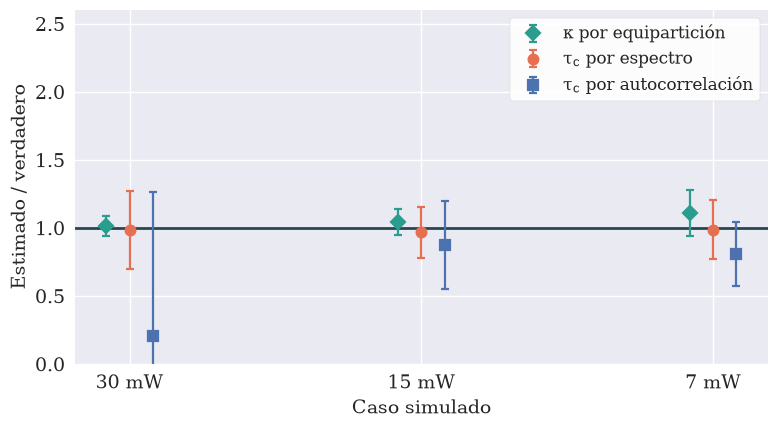

In [12]:
fig, ax = plt.subplots(figsize=(8, 4.5))
nombres = ["30 mW", "15 mW", "7 mW"]
for k, (estim, c, mk, lab) in enumerate((("kappa_equiparticion", SERIE1, "D", r"$\kappa$ por equipartición"),
                                         ("tau_espectro", SERIE2, "o", r"$\tau_c$ por espectro"),
                                         ("tau_autocorrelacion", AZUL, "s", r"$\tau_c$ por autocorrelación"))):
    v = val[val.estimador == estim].set_index("descripcion").reindex(nombres)
    xs = np.arange(len(nombres)) + 0.08 * (k - 1)
    ax.errorbar(xs, 1 + v.sesgo_pct / 100, yerr=v.dispersion_pct / 100, fmt=mk, color=c, mfc=c, mec=c, **EB, label=lab)
ax.axhline(1, color=AJUSTE, lw=2, zorder=2)
ax.set_xticks(range(len(nombres))); ax.set_xticklabels(["30 mW", "15 mW", "7 mW"])
ax.set_xlabel("Caso simulado"); ax.set_ylabel("Estimado / verdadero"); ax.set_ylim(0, 2.6)
ax.legend(loc="upper right", **LEY)
guardar(fig, "validacion_sinteticos")

**Qué dicen los sintéticos** (cada punto es la mediana de 150 series; la barra, cuánto se dispersa una medición sola).

- **Equipartición y Boltzmann** no tienen sesgo a 30 mW y sobreestiman $\kappa$ 4 % a 15 mW y 10 % a 7 mW (la parábola que se resta se lleva algo de la varianza cuando $\tau_c$ es largo). La dispersión de una medición es de 8 a 17 %: igual o mayor que el sesgo. No se corrige.
- **Autocorrelación**: a 30 mW **no sirve** ($\tau_c$ de 30 ms contra un período de 78 ms: la correlación a un cuadro es 0.03 y se pierde en el ruido). A 15 y 7 mW da $\tau_c$ con −13 a −21 % de sesgo y ± 25–30 % de dispersión.
- **Espectro**: da $\tau_c$ con sesgo menor que 10 % en todos los casos **si el ruido y la exposición que se le dicen son los verdaderos**. A 30 mW eso es engañoso: suponer mal $W$ cambia $\tau_c$ entre −23 y +54 %, y $\kappa$ de equipartición entre −25 y +29 %. **A 30 mW $\tau_c$ no se mide: se deduce de lo que se suponga para $W$ y para el ruido.**

## 6. Rigidez por escalón, por eje y por método

La exposición $W$ no se conoce (sección 9). Todo se calcula con $W = 0$, $W = dt/2$ y $W = dt$ ($dt$ = período entre cuadros). El valor central es $W = dt/2$. Los errores son por bootstrap de 12 bloques de ~2 s (las muestras están correlacionadas); el del espectro es el de la matriz de Fisher.

In [13]:
tab, det = po.analizar_escalones(cu, ru, GAMMA, T, n_boot=300)
tab["err_kappa_total"] = np.hypot(tab.err_kappa_equiparticion, tab.err_kappa_ruido)
# tabla para guardar: una fila por grabación, escalón y eje; W = dt/2 y, para equipartición, también W = 0 y W = dt
c = tab[tab.W_rel == 0.5].copy()
for wr, nom in ((0.0, "W0"), (1.0, "Wdt")):
    o = tab[tab.W_rel == wr].set_index(["grabacion", "escalon", "eje"])
    c["kappa_equiparticion_" + nom] = o.kappa_equiparticion.reindex(pd.MultiIndex.from_frame(c[["grabacion", "escalon", "eje"]])).values
    c["tau_espectro_" + nom] = o.tau_espectro.reindex(pd.MultiIndex.from_frame(c[["grabacion", "escalon", "eje"]])).values
# tau_c "resuelto": más largo que un cuadro, con error < 40 % y con el ruido por debajo del 30 % de la varianza
# (si el ruido pesa más, el ajuste del espectro reparte mal entre ruido y señal)
c["resuelto"] = (c.tau_espectro > c["dt"]) & (c.err_tau_espectro < 0.4 * c.tau_espectro) & (c.ruido_um2 < 0.3 * c.var_um2)
c["gamma_kappa_tau_1e8"] = c.kappa_equiparticion * 1e-6 * c.tau_espectro * 1e8
c["err_gamma_kappa_tau_1e8"] = c.gamma_kappa_tau_1e8 * np.hypot(c.err_kappa_total / c.kappa_equiparticion, c.err_tau_espectro / c.tau_espectro)
ESC = c.drop(columns=["tau_equiparticion", "err_tau_equiparticion", "tau_boltzmann", "err_tau_boltzmann", "W_rel"])
csv(ESC, "potencia_escalones.csv")
csv(tab.drop(columns=["tau_equiparticion", "err_tau_equiparticion", "tau_boltzmann", "err_tau_boltzmann"]), "potencia_escalones_por_exposicion.csv")

v = ESC[["grabacion", "potencia_mW", "eje", "n", "var_um2", "ruido_um2", "kappa_equiparticion_W0", "kappa_equiparticion",
         "kappa_equiparticion_Wdt", "err_kappa_equiparticion", "err_kappa_ruido", "kappa_boltzmann", "kappa_msd", "kappa_espectro",
         "err_kappa_espectro"]].copy()
v["var_um2"] *= 1e6; v["ruido_um2"] *= 1e6
v.columns = ["grabación", "P [mW]", "eje", "n", "Var [nm²]", "ruido² [nm²]", "κ eq W=0", "κ eq W=dt/2", "κ eq W=dt", "± estad.", "± ruido",
             "κ Boltz.", "κ MSD", "κ espectro", "± esp."]
print("RIGIDEZ [pN/µm]. 'eq' = equipartición. Boltzmann, MSD y espectro con W = dt/2; espectro = gamma/tau_c.")
print(v.round({"Var [nm²]": 0, "ruido² [nm²]": 0}).round(2).to_string(index=False))

RIGIDEZ [pN/µm]. 'eq' = equipartición. Boltzmann, MSD y espectro con W = dt/2; espectro = gamma/tau_c.
          grabación  P [mW] eje   n  Var [nm²]  ruido² [nm²]  κ eq W=0  κ eq W=dt/2  κ eq W=dt  ± estad.  ± ruido  κ Boltz.  κ MSD  κ espectro  ± esp.
            LASER 5    30.0   x 335     1850.0         488.0      3.00         2.03       1.65      0.13     0.15      2.04   2.36        1.25    0.27
            LASER 5    30.0   y 335     2073.0         372.0      2.40         1.71       1.42      0.09     0.08      1.73   1.89        1.33    0.27
            LASER 5    25.0   x 335     2584.0         488.0      1.95         1.46       1.23      0.15     0.07      1.47   1.69        1.06    0.20
            LASER 5    25.0   y 335     3068.0         372.0      1.52         1.19       1.02      0.13     0.03      1.19   1.33        0.80    0.13
            LASER 5    20.0   x 335     3235.0         488.0      1.49         1.17       1.01      0.10     0.04      1.16   1.37        1.02

In [14]:
v = ESC[["grabacion", "potencia_mW", "eje", "rho1", "tau_autocorrelacion", "err_tau_autocorrelacion", "tau_espectro_W0", "tau_espectro",
         "tau_espectro_Wdt", "err_tau_espectro", "tau_msd", "f_c_espectro", "resuelto", "gamma_kappa_tau_1e8", "err_gamma_kappa_tau_1e8"]].copy()
for k in ("tau_autocorrelacion", "err_tau_autocorrelacion", "tau_espectro_W0", "tau_espectro", "tau_espectro_Wdt", "err_tau_espectro", "tau_msd"):
    v[k] *= 1e3
v.columns = ["grabación", "P [mW]", "eje", "ρ(1 cuadro)", "τ autocorr.", "±", "τ esp. W=0", "τ esp. W=dt/2", "τ esp. W=dt", "± esp.", "τ MSD",
             "f_c esp. [Hz]", "resuelto", "γ=κτ [1e-8]", "± γ"]
print("TIEMPO DE RELAJACIÓN [ms]. Período entre cuadros: 76 ms (LASER 5) y 80 ms (BARRIDO POTENCIAS 2); Nyquist 6.6 y 6.3 Hz.")
red = {k: 0 for k in v.columns if k.startswith(("τ", "±"))}
red.update({"ρ(1 cuadro)": 2, "f_c esp. [Hz]": 1, "γ=κτ [1e-8]": 1, "± γ": 1, "± esp.": 0, "±": 0})
print(v.round(red).to_string(index=False))

TIEMPO DE RELAJACIÓN [ms]. Período entre cuadros: 76 ms (LASER 5) y 80 ms (BARRIDO POTENCIAS 2); Nyquist 6.6 y 6.3 Hz.
          grabación  P [mW] eje  ρ(1 cuadro)  τ autocorr.     ±  τ esp. W=0  τ esp. W=dt/2  τ esp. W=dt  ± esp.  τ MSD  f_c esp. [Hz]  resuelto  γ=κτ [1e-8]  ± γ
            LASER 5    30.0   x         0.19        115.0 801.0        59.0           47.0         29.0    10.0   50.0            3.4     False          9.5  2.3
            LASER 5    30.0   y         0.22        105.0 103.0        55.0           44.0         27.0     9.0   46.0            3.6     False          7.5  1.6
            LASER 5    25.0   x         0.26        185.0 137.0        72.0           55.0         33.0    10.0   73.0            2.9     False          8.0  1.8
            LASER 5    25.0   y         0.37         66.0  33.0        90.0           74.0         50.0    12.0   62.0            2.2     False          8.8  1.8
            LASER 5    20.0   x         0.31        513.0 616.0        

### Forma del pozo

$U(x) = -k_BT \ln P(x)$ con el histograma de posiciones de cada escalón (sin la deriva lenta), en unidades de $k_BT$ y con el mínimo de la parábola ajustada en cero. Es el pozo **aparente**: el histograma es el de la posición medida, ensanchado por el ruido y angostado por la exposición; las correcciones entran en $\kappa$ (tabla de arriba), no en el dibujo.

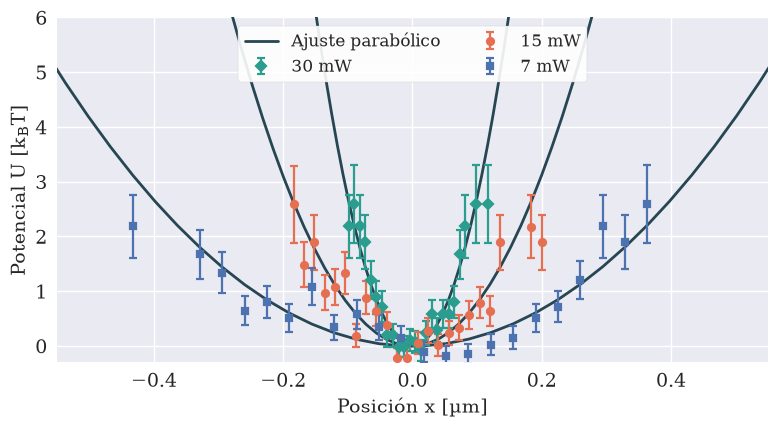

In [15]:
filas = []
for g in po.BARRIDOS:
    for eje in "xy":
        fig, ax = plt.subplots(figsize=(8, 4.5))
        for n, c_, mk in ((1, SERIE1, "D"), (4, SERIE2, "o"), (5, AZUL, "s")):
            gr = det[(g, n, eje, 0.5)]["graficos"]
            kTJ = po.KB * T
            x = gr["x_hist"] * 1e6
            U0 = np.nanmin(gr["U_ajuste"])
            ok = np.isfinite(gr["U"]) & (gr["err_U"] / kTJ < 0.75)
            P = esc[(esc.grabacion == g) & (esc.n == n)].potencia_mW.iloc[0]
            ax.errorbar(x[ok], (gr["U"][ok] - U0) / kTJ, yerr=gr["err_U"][ok] / kTJ, fmt=mk, color=c_, mfc=c_, mec=c_,
                        **{**EB, "ms": 5}, label="%g mW" % P)
            ax.plot(x, (gr["U_ajuste"] - U0) / kTJ, color=AJUSTE, lw=2, zorder=2, label="Ajuste parabólico" if n == 5 else None)
            for xi, Ui, ei, Ua in zip(x, gr["U"], gr["err_U"], gr["U_ajuste"]):
                filas.append(dict(grabacion=g, escalon=n, potencia_mW=P, eje=eje, x_um=xi, U_kT=(Ui - U0) / kTJ,
                                  err_U_kT=ei / kTJ, U_parabola_kT=(Ua - U0) / kTJ))
        ax.set_xlabel(r"Posición $%s$ [µm]" % eje); ax.set_ylabel(r"Potencial $U$ [$k_BT$]")
        ax.set_ylim(-0.3, 6); ax.set_xlim(-0.55, 0.55)
        ax.legend(loc="upper center", ncol=2, **LEY)
        guardar(fig, "potencial_%s_%s" % (g.replace(" ", "_"), eje))
        if not (g == "LASER 5" and eje == "x"):
            plt.close(fig)
# los potenciales de TODOS los escalones van al CSV
filas = []
for (g, n, eje, wr), dd in det.items():
    if wr != 0.5:
        continue
    gr = dd["graficos"]; kTJ = po.KB * T; U0 = np.nanmin(gr["U_ajuste"])
    P = esc[(esc.grabacion == g) & (esc.n == n)].potencia_mW.iloc[0]
    for xi, Ui, ei, Ua in zip(gr["x_hist"] * 1e6, gr["U"], gr["err_U"], gr["U_ajuste"]):
        filas.append(dict(grabacion=g, escalon=n, potencia_mW=P, eje=eje, x_um=xi, U_kT=(Ui - U0) / kTJ,
                          err_U_kT=ei / kTJ, U_parabola_kT=(Ua - U0) / kTJ))
csv(pd.DataFrame(filas), "potencia_potenciales.csv")

In [16]:
# ¿es parabólico y simétrico? Asimetría y curtosis de cada tramo contra las de un pozo armónico simulado igual
filas = []
for _, f in ESC.iterrows():
    A, K = po.nulo_armonico(int(f.n), f["dt"], max(f.tau_espectro, 0.01), max(f.var_psd_um2, 1e-5), f.W_s, f.ruido_um2, n_rep=300,
                            rng=int(f.escalon))
    filas.append(dict(grabacion=f.grabacion, potencia_mW=f.potencia_mW, eje=f.eje, asimetria=f.asimetria,
                      asimetria_esperada_sd=A.std(), z_asimetria=f.asimetria / A.std(), curtosis_exceso=f.curtosis_exceso,
                      curtosis_esperada_media=K.mean(), curtosis_esperada_sd=K.std(), z_curtosis=(f.curtosis_exceso - K.mean()) / K.std(),
                      chi2_red_parabola=f.chi2_boltzmann, no_cuadratico_a_2sigma=f.anarmonia_2s, corr_xy=f.corr_xy))
forma = pd.DataFrame(filas)
csv(forma, "potencia_forma_del_pozo.csv")
print(forma.round(2).to_string(index=False))
print("\n|z| > 2 en asimetría: %d de %d tramos; en curtosis: %d de %d (por azar se esperan ~1)"
      % ((forma.z_asimetria.abs() > 2).sum(), len(forma), (forma.z_curtosis.abs() > 2).sum(), len(forma)))
kx = ESC[ESC.eje == "x"].set_index(["grabacion", "potencia_mW"])
ky = ESC[ESC.eje == "y"].set_index(["grabacion", "potencia_mW"])
an = pd.DataFrame(dict(ky_sobre_kx=ky.kappa_equiparticion / kx.kappa_equiparticion))
an["err"] = an.ky_sobre_kx * np.hypot(kx.err_kappa_total / kx.kappa_equiparticion, ky.err_kappa_total / ky.kappa_equiparticion)
print("\nAnisotropía κ_y/κ_x por escalón:"); print(an.round(2).to_string())
for g in po.BARRIDOS:
    a = an.loc[g]; w = 1 / a["err"] ** 2
    print("%s: κ_y/κ_x medio = %.2f ± %.2f (los cinco escalones); sin 7 mW: %.2f"
          % (g, (w * a.ky_sobre_kx).sum() / w.sum(), 1 / np.sqrt(w.sum()), (w * a.ky_sobre_kx)[a.index > 10].sum() / w[a.index > 10].sum()))
print("asimetría de x negativa en %d de %d tramos" % ((forma[forma.eje == "x"].asimetria < 0).sum(), (forma.eje == "x").sum()))

          grabacion  potencia_mW eje  asimetria  asimetria_esperada_sd  z_asimetria  curtosis_exceso  curtosis_esperada_media  curtosis_esperada_sd  z_curtosis  chi2_red_parabola  no_cuadratico_a_2sigma  corr_xy
            LASER 5         30.0   x      -0.18                   0.12        -1.45             0.53                    -0.02                  0.26        2.13               0.56                    0.14     0.11
            LASER 5         30.0   y      -0.05                   0.12        -0.43            -0.08                    -0.01                  0.26       -0.28               1.23                    0.06     0.11
            LASER 5         25.0   x      -0.25                   0.14        -1.84             0.39                    -0.03                  0.25        1.68               1.13                    0.17     0.06
            LASER 5         25.0   y       0.12                   0.14         0.90            -0.24                    -0.03                  0.26     

### Autocorrelación y espectro

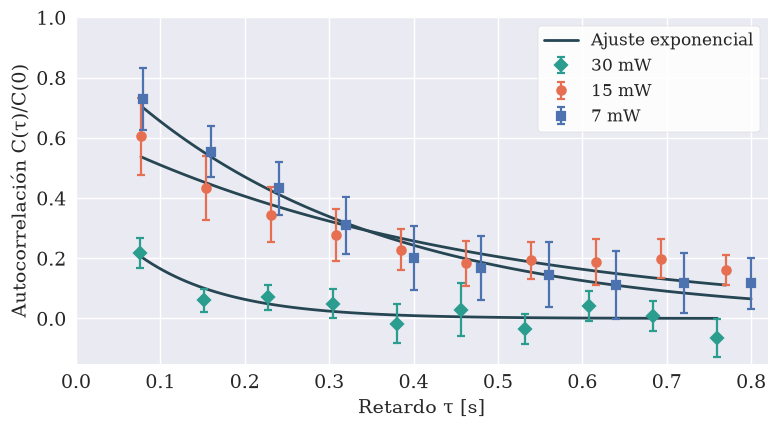

In [17]:
g, eje = "LASER 5", "y"
fig, ax = plt.subplots(figsize=(8, 4.5))
filas = []
for n, c_, mk in ((1, SERIE1, "D"), (4, SERIE2, "o"), (5, AZUL, "s")):
    dd = det[(g, n, eje, 0.5)]
    C, eC = po.autocovarianza(dd["x"], 10)
    f = ESC[(ESC.grabacion == g) & (ESC.escalon == n) & (ESC.eje == eje)].iloc[0]
    lag = np.arange(11) * f["dt"]
    ax.errorbar(lag[1:], C[1:] / C[0], yerr=eC[1:] / C[0], fmt=mk, color=c_, mfc=c_, mec=c_, **{**EB, "ms": 6}, label="%g mW" % f.potencia_mW)
    tt = np.linspace(f["dt"], lag[-1], 100)
    ax.plot(tt, f.amp_acf_um2 / C[0] * np.exp(-tt / f.tau_autocorrelacion), color=AJUSTE, lw=2, zorder=2,
            label="Ajuste exponencial" if n == 5 else None)
ax.set_xlabel(r"Retardo $\tau$ [s]"); ax.set_ylabel(r"Autocorrelación $C(\tau)/C(0)$")
ax.set_ylim(-0.15, 1); ax.set_xlim(0, 0.82); ax.legend(loc="upper right", **LEY)
guardar(fig, "autocorrelacion")

filas = []
for (g_, n, e_, wr), dd in det.items():
    if wr != 0.5:
        continue
    C, eC = po.autocovarianza(dd["x"], 10)
    f = ESC[(ESC.grabacion == g_) & (ESC.escalon == n) & (ESC.eje == e_)].iloc[0]
    for k in range(11):
        filas.append(dict(grabacion=g_, escalon=n, potencia_mW=f.potencia_mW, eje=e_, retardo_s=k * f["dt"], C_um2=C[k], err_C_um2=eC[k],
                          ajuste_um2=f.amp_acf_um2 * np.exp(-k * f["dt"] / f.tau_autocorrelacion) if k else np.nan))
csv(pd.DataFrame(filas), "potencia_autocorrelacion.csv")

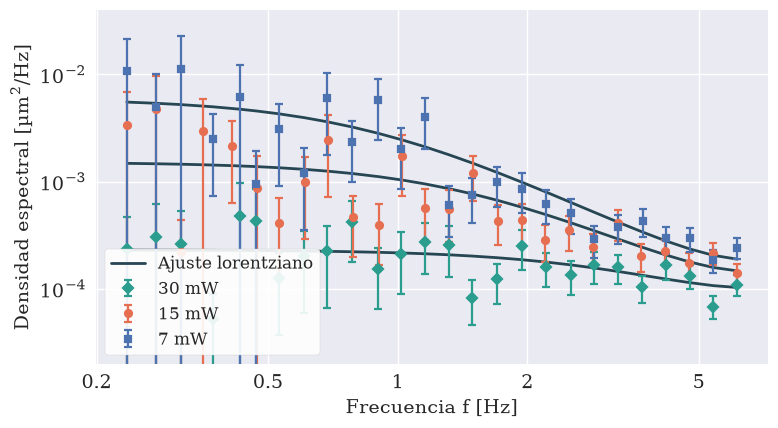

In [18]:
g, eje = "LASER 5", "y"
fig, ax = plt.subplots(figsize=(8, 4.5))
for n, c_, mk in ((1, SERIE1, "D"), (4, SERIE2, "o"), (5, AZUL, "s")):
    gr = det[(g, n, eje, 0.5)]["graficos"]
    f = ESC[(ESC.grabacion == g) & (ESC.escalon == n) & (ESC.eje == eje)].iloc[0]
    ok = gr["f"] >= 0.2
    ax.errorbar(gr["f"][ok], gr["psd"][ok] * 1e12, yerr=gr["psd"][ok] * 1e12 / np.sqrt(gr["psd_n"][ok]), fmt=mk, color=c_, mfc=c_, mec=c_,
                **{**EB, "ms": 5}, label="%g mW" % f.potencia_mW)
    ax.plot(gr["f"][ok], gr["psd_ajuste"][ok] * 1e12, color=AJUSTE, lw=2, zorder=2, label="Ajuste lorentziano" if n == 5 else None)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks([0.2, 0.5, 1, 2, 5]); ax.set_xticklabels(["0.2", "0.5", "1", "2", "5"]); ax.xaxis.set_minor_formatter(NullFormatter())
ax.set_ylim(2e-5, 4e-2)
ax.set_xlabel(r"Frecuencia $f$ [Hz]"); ax.set_ylabel(r"Densidad espectral [µm$^2$/Hz]")
ax.legend(loc="lower left", **LEY)
guardar(fig, "espectro")
filas = []
for (g_, n, e_, wr), dd in det.items():
    if wr != 0.5:
        continue
    gr = dd["graficos"]
    for a, b, c_, d_ in zip(gr["f"], gr["psd"], gr["psd_ajuste"], gr["psd_n"]):
        filas.append(dict(grabacion=g_, escalon=n, eje=e_, f_Hz=a, psd_um2_Hz=b * 1e12, ajuste_um2_Hz=c_ * 1e12, frecuencias_promediadas=int(d_)))
csv(pd.DataFrame(filas), "potencia_espectros.csv")

**Lectura.**

- **Rigidez.** A 30 mW, $\kappa_x \approx 2.0$–$2.1$ pN/µm y $\kappa_y \approx 1.6$–$1.7$ pN/µm en las dos grabaciones (con $W = dt/2$). Entre $W = 0$ y $W = dt$ el valor va de 3.0–3.2 a 1.7 en $x$: **la exposición desconocida pesa más que el error estadístico** (± 6 a 20 %) a potencia alta, y casi nada a 7 mW. Equipartición, Boltzmann y MSD usan la misma varianza y coinciden; no son tres mediciones independientes. La columna "κ espectro" es $\gamma/\tau_c$ y solo vale donde $\tau_c$ se resuelve.
- **Ruido.** En `BARRIDO POTENCIAS 2`, eje $x$, a 30 mW el ruido es el 55 % de la varianza: ahí $\kappa$ tiene ± 25 % solo por la incerteza del ruido.
- **Forma del pozo.** Dentro de lo que la partícula explora (± 0.1 µm a 30 mW, ± 0.4 µm a 7 mW; hasta 3–5 $k_BT$) el pozo es **parabólico**: el $\chi^2$ de la parábola es ~1 y la curtosis es la de un pozo armónico simulado con el mismo largo. **Simétrico, casi**: la asimetría de $x$ es negativa en 8 de 10 tramos (cola hacia −x, el lado al que empuja el flujo) y tres tramos de 20 se apartan más de 2.5 desvíos de lo que da un pozo armónico. Es chico (|asimetría| ≤ 0.6) y no cambia $\kappa$ más que su error. No hay correlación entre $x$ e $y$ (|ρ| < 0.3, sin signo fijo).
- **$x$ contra $y$.** En `LASER 5`, $\kappa_y/\kappa_x = 0.81 \pm 0.06$ de 30 a 15 mW (a 7 mW se invierte: 1.75 ± 0.35). En `BARRIDO POTENCIAS 2` son compatibles (0.93 ± 0.10). **Una anisotropía de ~20 %, que no se repite en la segunda grabación.** En `atrapada.csv` $y$ parecía moverse mucho más que $x$: era en buena parte la mancha del láser.
- El ancho del pozo (dónde deja de ser parabólico) no se alcanza con el movimiento térmico: sale del análisis por arrastre (PINZAS 3, ~1.1 µm).
- **$\tau_c$ y $f_c$.** La correlación a un cuadro crece de 0.2 a 0.8 al bajar la potencia en `LASER 5` (de 0.1–0.3 a 0.45 en `BARRIDO POTENCIAS 2`): el tiempo de relajación se alarga, como se esperaba. Pero **solo se resuelve a 15 y 7 mW en `LASER 5`** ($\tau_c \approx 0.10$ s y 0.19–0.32 s; $f_c \approx 1.6$ y 0.5–0.9 Hz), justo a 20 mW en $y$, **y a 7 mW en `BARRIDO POTENCIAS 2`** (0.10 s, 1.6 Hz). A 20–30 mW $\tau_c$ es más corto que un cuadro, $f_c$ queda cerca o por encima de Nyquist (6.3–6.6 Hz) y el valor del espectro depende de $W$ (cambia a la mitad entre $W = 0$ y $W = dt$): no es una medición. En el eje $x$ de `BARRIDO POTENCIAS 2` el espectro da $\tau_c$ largos a potencia alta, pero ahí el ruido es más del 30 % de la varianza y el ajuste no es confiable.
- La autocorrelación no es una sola exponencial: le queda una cola lenta (figura, 15 mW). Hay un movimiento lento del equilibrio encima del de la trampa; por eso su $\tau_c$ sale más largo que el del espectro.

## 7. Rigidez contra potencia

          grabacion eje  W_rel     puntos  ordenada_pN_um  err_ordenada  pendiente_pN_um_mW  err_pendiente  chi2  gl  P_cero_mW  err_P_cero
            LASER 5   x    0.5  30 a 7 mW          -0.394         0.046               0.075          0.005 4.199   3      5.283       0.356
            LASER 5   x    0.5 30 a 15 mW          -0.772         0.217               0.093          0.011 1.016   2      8.276       1.361
BARRIDO POTENCIAS 2   x    0.5  30 a 7 mW           0.230         0.143               0.060          0.013 0.070   3     -3.855       3.187
BARRIDO POTENCIAS 2   x    0.5 30 a 15 mW           0.298         0.631               0.056          0.032 0.058   2     -5.298      14.197
            LASER 5   y    0.5  30 a 7 mW          -0.162         0.041               0.055          0.004 9.942   3      2.954       0.598
            LASER 5   y    0.5 30 a 15 mW          -0.684         0.175               0.078          0.009 0.553   2      8.712       1.340
BARRIDO POTENCIAS 2 

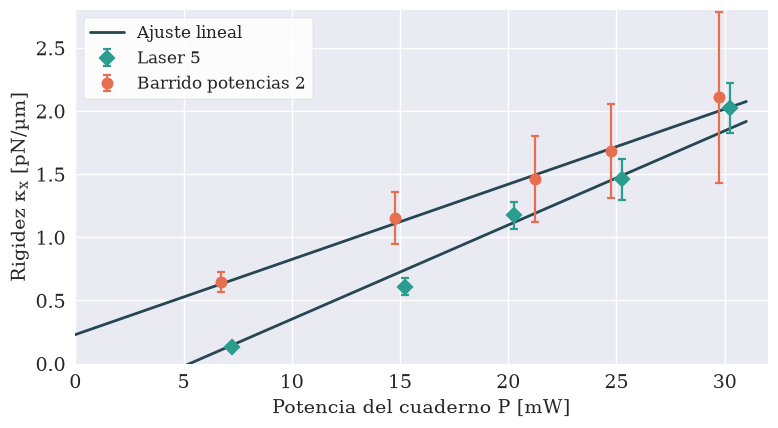

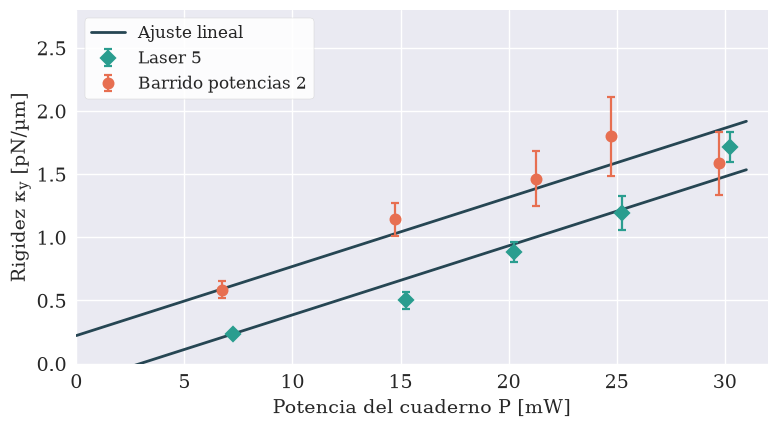

In [19]:
filas = []
for eje in "xy":
    fig, ax = plt.subplots(figsize=(8, 4.5))
    for g in po.BARRIDOS:
        s = ESC[(ESC.grabacion == g) & (ESC.eje == eje)]
        dx = 0.25 if g == "LASER 5" else -0.25
        ax.errorbar(s.potencia_mW + dx, s.kappa_equiparticion, yerr=s.err_kappa_total, fmt=MARCA[g], color=COLOR[g], mfc=COLOR[g],
                    mec=COLOR[g], **EB, label="Laser 5" if g == "LASER 5" else "Barrido potencias 2")
        for wr in (0.0, 0.5, 1.0):
            o = tab[(tab.grabacion == g) & (tab.eje == eje) & (tab.W_rel == wr)]
            for sel, nom in ((o.escalon <= 5, "30 a 7 mW"), (o.escalon <= 4, "30 a 15 mW")):
                f = po.ajuste_lineal(o.potencia_mW[sel], o.kappa_equiparticion[sel], o.err_kappa_total[sel])
                filas.append(dict(grabacion=g, eje=eje, W_rel=wr, puntos=nom, ordenada_pN_um=f["a"], err_ordenada=f["err_a"],
                                  pendiente_pN_um_mW=f["b"], err_pendiente=f["err_b"], chi2=f["chi2"], gl=f["gl"],
                                  P_cero_mW=f["x0"], err_P_cero=f["err_x0"]))
                if wr == 0.5 and nom == "30 a 7 mW":
                    pp = np.array([0, 31])
                    ax.plot(pp, f["a"] + f["b"] * pp, color=AJUSTE, lw=2, zorder=2, label="Ajuste lineal" if g == "LASER 5" else None)
    ax.set_xlim(0, 32); ax.set_ylim(0, 2.8)
    ax.set_xlabel(r"Potencia del cuaderno $P$ [mW]"); ax.set_ylabel(r"Rigidez $\kappa_%s$ [pN/µm]" % eje)
    ax.legend(loc="upper left", **LEY)
    guardar(fig, "kappa_potencia_%s" % eje)
rectas = pd.DataFrame(filas)
csv(rectas, "potencia_ajustes_kappa_potencia.csv")
print(rectas[rectas.W_rel == 0.5].round(3).to_string(index=False))

          grabacion eje  ordenada_nm2  err_ordenada_nm2  ruido_plantilla_nm2  pendiente_nm2_mW  err_pendiente  chi2  gl
            LASER 5   x       -1901.1             428.6                487.7          111304.0        11518.7  15.7   3
            LASER 5   y       -2530.7             412.8                372.1          138191.2        11407.5   1.4   3
BARRIDO POTENCIAS 2   x        1677.5             301.9               1544.3           38433.6         5529.6   0.6   3
BARRIDO POTENCIAS 2   y        1254.8             281.5               1020.9           39275.4         5612.6   4.3   3


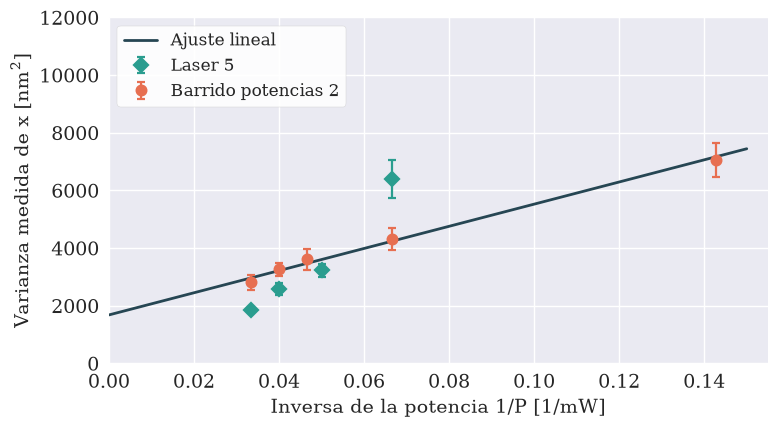

In [20]:
# varianza medida contra 1/P: si kappa = b·P, Var = ruido² + (kT·S/b)/P -> la ordenada es el ruido
fig, ax = plt.subplots(figsize=(8, 4.5))
filas = []
for g in po.BARRIDOS:
    for eje in "xy":
        s = ESC[(ESC.grabacion == g) & (ESC.eje == eje)]
        err = s.var_um2 * 2 * s.err_kappa_equiparticion / s.kappa_equiparticion * (1 - s.ruido_um2 / s.var_um2) / 2 + 1e-9
        f = po.ajuste_lineal(1 / s.potencia_mW, s.var_um2 * 1e6, err * 1e6)
        filas.append(dict(grabacion=g, eje=eje, ordenada_nm2=f["a"], err_ordenada_nm2=f["err_a"], ruido_plantilla_nm2=s.ruido_um2.iloc[0] * 1e6,
                          pendiente_nm2_mW=f["b"], err_pendiente=f["err_b"], chi2=f["chi2"], gl=f["gl"]))
        if eje == "x":
            ax.errorbar(1 / s.potencia_mW, s.var_um2 * 1e6, yerr=err * 1e6, fmt=MARCA[g], color=COLOR[g], mfc=COLOR[g], mec=COLOR[g], **EB,
                        label="Laser 5" if g == "LASER 5" else "Barrido potencias 2")
            if g == "BARRIDO POTENCIAS 2":
                q = np.array([0, 0.15])
                ax.plot(q, f["a"] + f["b"] * q, color=AJUSTE, lw=2, zorder=2, label="Ajuste lineal")
ax.set_xlim(0, 0.155); ax.set_ylim(0, 12000)
ax.set_xlabel(r"Inversa de la potencia $1/P$ [1/mW]"); ax.set_ylabel(r"Varianza medida de $x$ [nm$^2$]")
ax.legend(loc="upper left", **LEY)
guardar(fig, "varianza_inversa_potencia")
vp = pd.DataFrame(filas); csv(vp, "potencia_ajustes_varianza_inversa_potencia.csv")
print(vp.round(1).to_string(index=False))

**$\kappa$ crece con la potencia en las dos grabaciones, pero no igual.**

- **`BARRIDO POTENCIAS 2`: compatible con $\kappa \propto P$.** La recta pasa cerca del origen (cruza el cero en $P_0 = -4 \pm 3$ mW con $W = dt/2$ y en $-1 \pm 2$ mW con $W = 0$, en los dos ejes) con pendiente 0.055–0.060 pN/µm por mW. La varianza medida contra $1/P$ es una recta cuya ordenada (1680 ± 300 nm² en $x$, 1250 ± 280 nm² en $y$) **coincide con el ruido medido con la plantilla** (1540 y 1020 nm²): chequeo independiente del ruido. (En la figura, el punto de 7 mW de `LASER 5`, 30 000 nm², queda fuera de la escala.)
- **`LASER 5`: no es proporcional.** $\kappa$ cae más rápido que $P$: entre 30 y 7 mW baja un factor 15 en $x$ y 7 en $y$ (la potencia, 4.3). La recta por los cinco puntos cruza el cero en $P_0 \approx 3$–$5$ mW con mal $\chi^2$ (4 y 10 con 3 grados de libertad), y por los cuatro de 30 a 15 mW en $P_0 \approx 8$–$9$ mW. El tiempo de relajación a 7 mW (0.2–0.3 s, contra 0.1 s en `BARRIDO POTENCIAS 2`) confirma que a "7 mW" la trampa de `LASER 5` es 3–4 veces más blanda: es la trampa, no el estimador.
- A 30 mW las dos coinciden. La diferencia está en los escalones bajos. **No se puede decir por qué**: que los valores del cuaderno no sean la potencia real en una de las dos (el rojo no sirve para verificarlo), que la partícula de `LASER 5` esté a otra altura, o que con la trampa floja el flujo la corra a una zona más blanda (a 7 mW el centro se corre 0.1 µm, ver sección 10).

## 8. $\tau_c$ y $f_c$ contra potencia, y $\gamma = \kappa\,\tau_c$

Si se conoce $\gamma$, la rigidez de equipartición predice $\tau_c = \gamma/\kappa$. La figura compara esa predicción con el $\tau_c$ medido (espectro, promedio de $x$ e $y$). Marcador hueco: no resuelto ($\tau_c$ menor que un cuadro o error mayor que 40 %).

gamma = kappa·tau_c en los 7 tramos resueltos (W = dt/2):
          grabacion  potencia_mW eje  kappa_equiparticion  tau_espectro  tau_autocorrelacion  gamma_kappa_tau_1e8  err_gamma_kappa_tau_1e8
            LASER 5         20.0   y                0.886         0.092                0.199                8.156                    1.510
            LASER 5         15.0   x                0.609         0.093                0.139                5.641                    1.109
            LASER 5         15.0   y                0.501         0.108                0.439                5.396                    1.135
            LASER 5          7.0   x                0.135         0.315                0.417                4.241                    1.303
            LASER 5          7.0   y                0.236         0.186                0.303                4.403                    0.937
BARRIDO POTENCIAS 2          7.0   x                0.645         0.097                0.147                

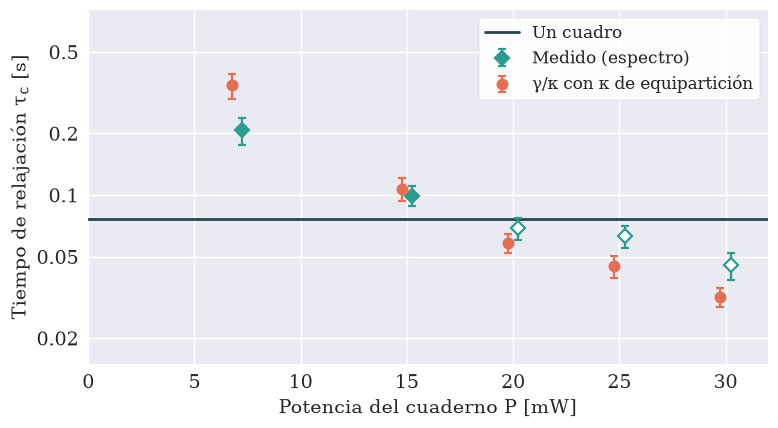

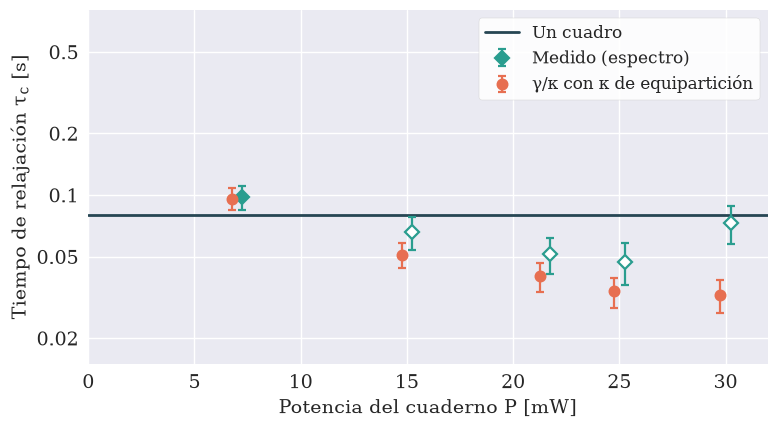

In [21]:
for g in po.BARRIDOS:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    s = ESC[ESC.grabacion == g]
    dt = s["dt"].iloc[0]
    P, tm, em, tp, ep, res = [], [], [], [], [], []
    for p_, v in s.groupby("potencia_mW"):
        w = 1 / v.err_tau_espectro ** 2
        P.append(p_); tm.append((w * v.tau_espectro).sum() / w.sum()); em.append(1 / np.sqrt(w.sum())); res.append(bool(v.resuelto.all()))
        pred = GAMMA / (v.kappa_equiparticion * 1e-6)
        tp.append(pred.mean()); ep.append(np.hypot((pred * v.err_kappa_total / v.kappa_equiparticion).mean() / np.sqrt(2), pred.mean() * ERR_GAMMA / GAMMA))
    P, tm, em, tp, ep, res = map(np.array, (P, tm, em, tp, ep, res))
    ax.errorbar(P[res] + 0.25, tm[res], yerr=em[res], fmt="D", color=SERIE1, mfc=SERIE1, mec=SERIE1, **EB, label="Medido (espectro)")
    ax.errorbar(P[~res] + 0.25, tm[~res], yerr=em[~res], fmt="D", color=SERIE1, mfc="white", mec=SERIE1, **EB)
    ax.errorbar(P - 0.25, tp, yerr=ep, fmt="o", color=SERIE2, mfc=SERIE2, mec=SERIE2, **EB, label=r"$\gamma/\kappa$ con $\kappa$ de equipartición")
    ax.axhline(dt, color=AJUSTE, lw=2, zorder=2, label="Un cuadro")
    ax.set_yscale("log"); ax.set_yticks([0.02, 0.05, 0.1, 0.2, 0.5]); ax.set_yticklabels(["0.02", "0.05", "0.1", "0.2", "0.5"])
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_xlim(0, 32); ax.set_ylim(0.015, 0.8)
    ax.set_xlabel(r"Potencia del cuaderno $P$ [mW]"); ax.set_ylabel(r"Tiempo de relajación $\tau_c$ [s]")
    ax.legend(loc="upper right", **LEY)
    guardar(fig, "tau_potencia_%s" % g.replace(" ", "_"))

r = ESC[ESC.resuelto]
w = 1 / r.err_gamma_kappa_tau_1e8 ** 2
gkt, egkt = (w * r.gamma_kappa_tau_1e8).sum() / w.sum(), 1 / np.sqrt(w.sum())
chi2 = (w * (r.gamma_kappa_tau_1e8 - gkt) ** 2).sum()
print("gamma = kappa·tau_c en los %d tramos resueltos (W = dt/2):" % len(r))
print(r[["grabacion", "potencia_mW", "eje", "kappa_equiparticion", "tau_espectro", "tau_autocorrelacion", "gamma_kappa_tau_1e8", "err_gamma_kappa_tau_1e8"]].round(3).to_string(index=False))
print("media pesada: (%.1f ± %.1f)·1e-8 N·s/m, chi2 = %.1f con %d gl (el error se agranda por sqrt(chi2/gl) -> ± %.1f)"
      % (gkt, egkt, chi2, len(r) - 1, egkt * max(1, np.sqrt(chi2 / (len(r) - 1)))))
print("con la partícula suelta (sección 4): (%.1f ± %.1f)·1e-8 N·s/m" % (GAMMA * 1e8, ERR_GAMMA * 1e8))
for wr in (0.0, 0.5, 1.0):
    o = tab[tab.W_rel == wr].merge(r[["grabacion", "escalon", "eje"]])
    gg = o.kappa_equiparticion * o.tau_espectro * 1e2
    eg = gg * np.hypot(o.err_kappa_total / o.kappa_equiparticion, o.err_tau_espectro / o.tau_espectro)
    ww = 1 / eg ** 2
    print("   con W = %.1f·dt en esos mismos tramos: media pesada %.1f·1e-8, media simple %.1f·1e-8"
          % (wr, (ww * gg).sum() / ww.sum(), gg.mean()))
ga = r.kappa_equiparticion * r.tau_autocorrelacion * 1e2
print("   con tau_c de la autocorrelación (no depende de W): media simple %.1f, mediana %.1f ·1e-8" % (ga.mean(), ga.median()))

- Donde $\tau_c$ se resuelve, **$\gamma = \kappa\,\tau_c = (5.4 \pm 0.5)\times10^{-8}$ N·s/m (con $W = dt/2$), igual que el de la difusión de la partícula suelta, $(5.9 \pm 0.5)\times10^{-8}$**, sin haber supuesto viscosidad ni radio: los dos caminos (cuánto se mueve y qué tan rápido vuelve) cierran. Con $W = 0$ daría 7.6 y con $W = dt$, 3.3: el acuerdo también apunta a $W \approx dt/2$ (sección 9).
- Respecto de Stokes con 24 % de glicerina y $R$ = 1.5 µm hace falta un factor 1.05–1.15 (Faxén con el centro a ~8 µm del vidrio, o un radio 10 % mayor). Con la receta de 58 % sobraría un factor 4: descartada.
- **Extrapolando**: con $\gamma$ medido y $\kappa$ de equipartición, a 30 mW $\tau_c = \gamma/\kappa \approx$ 28–37 ms y $f_c \approx$ 4.3–5.7 Hz ($W = dt/2$; de 18 a 45 ms según $W$ y el eje). Es lo que da el análisis por arrastre (26 ± 3 ms, PINZAS 3). No se puede medir directo con 13 cuadros por segundo.

## 9. La exposición $W$

No está en los archivos. Cuatro cosas la acotan, ninguna cierra sola:

1. **El estirado de las partículas durante una patada de la platina** (medición directa, pero en otra grabación). En `BARRIDO 2` (cuadros 1507–1509, imagen moviéndose a 100–150 µm/s) las partículas se ven como trazos. El largo del trazo es $v\,W$ y la distancia entre los centros de los trazos de cuadros seguidos es $v\,dt$: el cociente da $W/dt$. Esa grabación tiene otra configuración de cámara (10 cuadros por segundo y otro balance de color) que las dos de potencia, así que **no es una medición de $W$ para estas**; dice que la cámara se usaba con exposiciones largas, no de pocos ms.
2. **Consistencia con el arrastre.** El análisis de las patadas (PINZAS 3) da $\kappa/\gamma = 38 \pm 4$ s⁻¹ a 30 mW sin usar la varianza. Acá, $\kappa_x/\gamma$ a 30 mW depende de $W$.
3. **$\gamma = \kappa\,\tau_c$ contra la difusión** (sección 8): coinciden con $W = dt/2$ y no con 0 ni con $dt$.
4. **La forma del espectro**: la exposición atenúa las frecuencias altas. Se ajusta el espectro de todos los tramos con cada $W$ y se compara la verosimilitud.

Estirado en BARRIDO 2: W/dt = 0.40 (mediana de 7 trazos; desvío 0.10, error de la media 0.04)

kappa_x/gamma a 30 mW [1/s] según la exposición supuesta (gamma = 5.9·1e-8 N·s/m):
  LASER 5              W = 0.0 dt: 51 ± 6   W = 0.5 dt: 35 ± 3   W = 1.0 dt: 28 ± 3
  BARRIDO POTENCIAS 2  W = 0.0 dt: 55 ± 22   W = 0.5 dt: 36 ± 12   W = 1.0 dt: 29 ± 9

por arrastre (PINZAS 3):
         grabacion eje     k  err_k  tau_c_ms
         BARRIDO 1   x 38.00  7.554     26.32
BARRIDO STEPSIZE 2   x 38.78  4.214     25.79


W_sobre_dt                     0.02  0.20  0.40  0.60  0.80  1.00
grabacion           ruido_por                                    
BARRIDO POTENCIAS 2 1.0         0.0   0.7   2.1   4.3   7.9  13.8
                    1.5         3.1   2.0   1.0   0.3   0.0   0.7
LASER 5             1.0         0.0   4.1  11.0  21.3  37.5  64.5
                    1.5         0.0   3.3   8.9  17.8  32.1  56.4


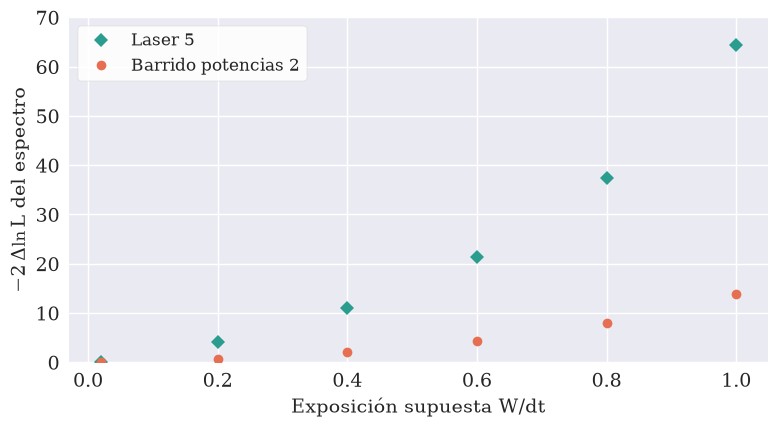

In [22]:
ruta = os.path.join(SALIDA, "potencia_exposicion_estirado.csv")
if os.path.exists(ruta):
    estirado = pd.read_csv(ruta)
else:
    estirado = po.exposicion_por_estirado("BARRIDO 2", 1505, 7, (0, -1))      # la imagen se mueve hacia arriba
    csv(estirado, "potencia_exposicion_estirado.csv")
print("Estirado en BARRIDO 2: W/dt = %.2f (mediana de %d trazos; desvío %.2f, error de la media %.2f)\n"
      % (estirado.W_sobre_dt.median(), len(estirado), estirado.W_sobre_dt.std(), estirado.W_sobre_dt.std() / np.sqrt(len(estirado))))
print("kappa_x/gamma a 30 mW [1/s] según la exposición supuesta (gamma = %.1f·1e-8 N·s/m):" % (GAMMA * 1e8))
o = tab[(tab.escalon == 1) & (tab.eje == "x")]
for g in po.BARRIDOS:
    v = o[o.grabacion == g]
    print("  %-20s" % g, "   ".join("W = %.1f dt: %.0f ± %.0f" % (f.W_rel, f.kappa_equiparticion * 1e-6 / GAMMA,
                                                                 f.err_kappa_total * 1e-6 / GAMMA) for _, f in v.iterrows()))
ruta = os.path.join(SALIDA, "pozo_ajustes.csv")
if os.path.exists(ruta):
    pz = pd.read_csv(ruta)
    print("\npor arrastre (PINZAS 3):")
    print(pz[pz.grabacion.isin(["BARRIDO 1", "BARRIDO STEPSIZE 2"])][["grabacion", "eje", "k", "err_k", "tau_c_ms"]].to_string(index=False))

Wr = np.array([0.02, 0.2, 0.4, 0.6, 0.8, 1.0])
fig, ax = plt.subplots(figsize=(8, 4.5))
filas = []
for g in po.BARRIDOS:
    series = [(dd["t"], dd["x"]) for (g_, n, e_, wr), dd in det.items() if g_ == g and wr == 0.5]
    s2 = [RUIDO[(g, e_)] for (g_, n, e_, wr), dd in det.items() if g_ == g and wr == 0.5]
    for fac in (1.0, 1.5):
        L = po.verosimilitud_exposicion(series, Wr, [s * fac for s in s2])
        for a, b in zip(Wr, L):
            filas.append(dict(grabacion=g, ruido_por=fac, W_sobre_dt=a, delta_2lnL=b))
        if fac == 1.0:
            ax.plot(Wr, L, MARCA[g], ms=7, color=COLOR[g], mec=COLOR[g], mfc=COLOR[g], zorder=3,
                    label="Laser 5" if g == "LASER 5" else "Barrido potencias 2")
ax.set_xlabel(r"Exposición supuesta $W/dt$"); ax.set_ylabel(r"$-2\,\Delta\ln L$ del espectro")
ax.set_ylim(0, 70); ax.legend(loc="upper left", **LEY)
guardar(fig, "exposicion_verosimilitud")
vw = pd.DataFrame(filas); csv(vw, "potencia_exposicion_verosimilitud.csv")
print(vw.pivot_table(index=["grabacion", "ruido_por"], columns="W_sobre_dt", values="delta_2lnL").round(1))

- **Estirado:** $W/dt \approx 0.40 \pm 0.10$ en `BARRIDO 2` (7 trazos; unos 40 ms).
- **Arrastre:** $\kappa_x/\gamma$ a 30 mW coincide con 38 ± 4 s⁻¹ si $W \approx dt/2$ (35–36); con $W = 0$ da 51–55 y con $W = dt$, 28–29. Eso deja **$W/dt \approx 0.5 \pm 0.35$**, con el supuesto de que el ruido es solo el de píxel (si el ruido real es mayor, $W$ tendría que ser más larga). Ojo: el análisis por arrastre usa las posiciones de `atrapada.csv`, contaminadas por el láser cerca del centro (sección 3).
- **$\kappa\,\tau_c$ contra difusión:** 7.6, 5.4 y 3.3 ×10⁻⁸ N·s/m con $W$ = 0, $dt/2$ y $dt$, contra 5.9 ± 0.5.
- **Espectro:** en `LASER 5` prefiere exposiciones cortas ($-2\Delta\ln L$ = 11 para $W = 0.4\,dt$ y 65 para $W = dt$); en `BARRIDO POTENCIAS 2` casi no distingue, y con 50 % más de ruido prefiere $W \approx 0.8\,dt$. Este test **confunde exposición con ruido blanco de más y con movimiento que no sea un Ornstein–Uhlenbeck puro** (hay una componente lenta: la autocorrelación no es una sola exponencial). No se usa para fijar $W$.
- **Se toma $W = dt/2$ (38–40 ms) como valor central y $W \in [0, dt]$ como incerteza sistemática.** Cuánto cambia cada resultado:

| | $W = 0$ | $W = dt/2$ | $W = dt$ |
|---|---|---|---|
| $\kappa_x$ a 30 mW (`LASER 5`) | 3.0 | 2.0 | 1.7 pN/µm |
| $\kappa_x$ a 15 mW (`LASER 5`) | 0.69 | 0.61 | 0.55 pN/µm |
| $\kappa_x$ a 7 mW (`LASER 5`) | 0.14 | 0.13 | 0.13 pN/µm |
| $\tau_c$ del espectro a 7 mW, $x$ (`LASER 5`) | 0.44 | 0.32 | 0.20 s |

(Los valores exactos están en `potencia_escalones_por_exposicion.csv`.) **La exposición hay que anotarla la próxima vez**: es la mayor incerteza de $\kappa$ a potencia alta.

## 10. Potencia baja: cuándo deja de estar atrapada

Después del cambio de los 151 s (a "< 7 mW" en `LASER 5` y a "3 mW" en `BARRIDO POTENCIAS 2`) la partícula se va del centro. La figura muestra su distancia al equilibrio y, como referencia, dónde estaría si el líquido la llevara a la velocidad de las partículas libres desde ese momento.

Velocidades en µm/s, en ventanas de 10 s
          grabacion  t_ini_s  x_um  y_um  distancia_um  vx_particula  vy_particula  vx_flujo  vy_flujo  libres  rojo_lejos_rel
            LASER 5      150 -1.48  0.61          1.62         -0.27          0.07     -0.26      0.15       9            0.47
            LASER 5      160 -3.27  1.16          3.52         -0.24         -0.08     -0.21      0.11       7            0.32
            LASER 5      170 -3.65  1.69          4.05         -0.02          0.31     -0.32      0.06       5            0.31
BARRIDO POTENCIAS 2      150  1.03  0.95          1.43          0.05          0.11     -0.08      0.08       9            0.55
BARRIDO POTENCIAS 2      160  1.72  1.48          2.30          0.12          0.17     -0.18      0.06       8            0.42
BARRIDO POTENCIAS 2      170  1.24  2.95          3.22         -0.03          0.18     -0.14      0.07       9            0.36
BARRIDO POTENCIAS 2      180  0.23  3.82          3.83          0.03  

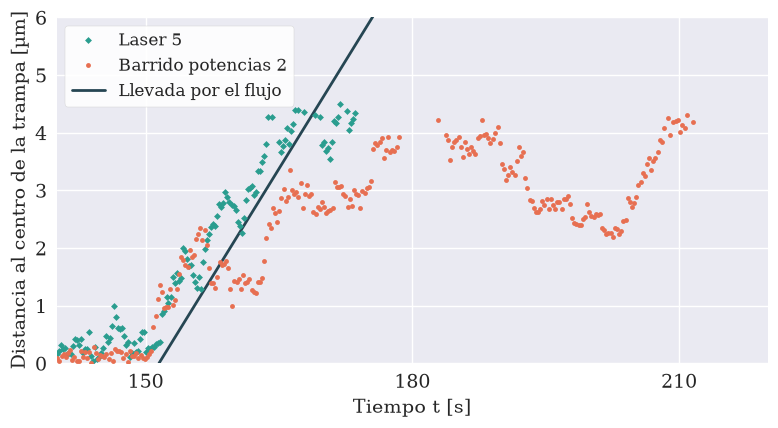

In [23]:
fig, ax = plt.subplots(figsize=(8, 4.5))
filas = []
for g in po.BARRIDOS:
    d = cu[(cu.grabacion == g) & (cu.t_s >= 140) & cu.xc_um.notna()]
    d = d[d.particula == d.particula.iloc[0]]                        # solo la partícula que estaba atrapada
    ax.plot(d.t_s[::3], np.hypot(d.xc_um, d.yc_um)[::3], MARCA[g], ms=3.5, color=COLOR[g], mec=COLOR[g], mfc=COLOR[g], zorder=3,
            label="Laser 5" if g == "LASER 5" else "Barrido potencias 2")
    fl = flujo[flujo.grabacion == g].iloc[0]
    for ta in range(150, 240, 10):
        v = d[(d.t_s >= ta) & (d.t_s < ta + 10)]
        if len(v) < 30:
            continue
        libres = po.flujo_libres(g, t_min=ta, t_max=ta + 10, largo_min=60)
        filas.append(dict(grabacion=g, t_ini_s=ta, x_um=v.xc_um.mean(), y_um=v.yc_um.mean(), distancia_um=np.hypot(v.xc_um, v.yc_um).mean(),
                          vx_particula=np.polyfit(v.t_s, v.xc_um, 1)[0], vy_particula=np.polyfit(v.t_s, v.yc_um, 1)[0],
                          vx_flujo=libres.vx_um_s.median(), vy_flujo=libres.vy_um_s.median(), libres=len(libres),
                          rojo_lejos_rel=v.rojo_lejos.mean() / cu[(cu.grabacion == g) & (cu.t_s < 30)].rojo_lejos.mean()))
tt = np.array([151.5, 190])
ax.plot(tt, 0.25 * (tt - 151.5), color=AJUSTE, lw=2, zorder=2, label="Llevada por el flujo")
ax.set_xlim(140, 220); ax.set_ylim(0, 6); ax.set_xticks(range(150, 211, 30))
ax.set_xlabel(r"Tiempo $t$ [s]"); ax.set_ylabel("Distancia al centro de la trampa [µm]")
ax.legend(loc="upper left", **LEY)
guardar(fig, "potencia_baja_distancia")
baja = pd.DataFrame(filas); csv(baja, "potencia_baja.csv")
print("Velocidades en µm/s, en ventanas de 10 s"); print(baja.round(2).to_string(index=False))

In [24]:
# ¿se corre el centro de equilibrio con la potencia? Media por escalón respecto del primero, y lo que predice el arrastre del flujo
filas = []
for g in po.BARRIDOS:
    fl = flujo[flujo.grabacion == g].iloc[0]
    s = ESC[ESC.grabacion == g].set_index(["escalon", "eje"])
    for n in range(1, 6):
        f = dict(grabacion=g, potencia_mW=s.loc[(n, "x")].potencia_mW)
        for eje, v in (("x", fl.vx_um_s), ("y", fl.vy_um_s)):
            k = s.loc[(n, eje)]
            f["corrimiento_%s_nm" % eje] = 1e3 * (k.media_um - s.loc[(1, eje)].media_um)
            f["err_%s_nm" % eje] = 1e3 * np.sqrt(k.var_um2 / (k.n * k["dt"] / (2 * max(k.tau_espectro, k["dt"]))))
            f["arrastre_%s_nm" % eje] = 1e3 * (GAMMA * v * 1e-6 / (k.kappa_equiparticion * 1e-6) - GAMMA * v * 1e-6 / (s.loc[(1, eje)].kappa_equiparticion * 1e-6)) * 1e6
        filas.append(f)
centro = pd.DataFrame(filas); csv(centro, "potencia_centro.csv")
print(centro.round(0).to_string(index=False))

          grabacion  potencia_mW  corrimiento_x_nm  err_x_nm  arrastre_x_nm  corrimiento_y_nm  err_y_nm  arrastre_y_nm
            LASER 5         30.0               0.0       3.0            0.0               0.0       4.0            0.0
            LASER 5         25.0               2.0       4.0           -2.0              -3.0       4.0            2.0
            LASER 5         20.0              14.0       4.0           -4.0              36.0       6.0            5.0
            LASER 5         15.0             -25.0       7.0          -14.0              50.0       8.0           14.0
            LASER 5          7.0            -113.0      27.0          -84.0              17.0      15.0           35.0
BARRIDO POTENCIAS 2         30.0               0.0       5.0            0.0               0.0       4.0            0.0
BARRIDO POTENCIAS 2         25.0               3.0       5.0           -1.0              18.0       4.0           -1.0
BARRIDO POTENCIAS 2         22.0              17

**Qué se puede decir.**

- **`LASER 5`, "< 7 mW" (150–180 s):** la partícula se va a ~0.2 µm/s hacia −x, +y, el sentido y la velocidad del flujo, y se pierde a los 4 µm. **No queda atrapada.** A 7 mW la fuerza del flujo ($\gamma v \approx 0.015$ pN) ya corría el equilibrio 0.1 µm; un poco menos de potencia y el flujo gana.
- **`BARRIDO POTENCIAS 2`, "3 mW" y "< 3 mW" (150–210 s):** la partícula deambula entre 1 y 4 µm del centro durante **60 s**, mientras el flujo se habría llevado a una partícula libre unos 14 µm. **Algo la retiene todavía**, a distancias mayores que el ancho del pozo medido por arrastre a 30 mW (~1.1 µm). A los 211 s el rojo cae a cero y la partícula se va con el flujo.
- **No se puede** sacar de acá una rigidez, un ancho de captura ni una profundidad del pozo a esas potencias: la partícula no está en equilibrio (se mueve con el flujo y contra él), la fuerza del flujo no se conoce en el lugar de la trampa mejor que ± 30 %, y son una sola salida por grabación. Como cota: a 7 mW la partícula explora 4–5 $k_BT$ de pozo sin escaparse en 25 s, así que la profundidad a 7 mW es mayor que eso.
- **El centro de equilibrio se corre con la potencia**: en `LASER 5`, −110 nm en $x$ a 7 mW, en el sentido del flujo y del orden de lo que predice el arrastre ($\gamma v/\kappa \approx -85$ nm). En `BARRIDO POTENCIAS 2` se corre +50 nm en $x$ y +60 nm en $y$ entre 30 y 7 mW, bastante más de lo que da el arrastre (10 nm) y, en $x$, en contra del flujo. El corrimiento es monótono en el tiempo, así que **no se distingue** de una deriva lenta de la platina o del láser, ni de un cambio de puntería del láser con la corriente.

## 11. Conclusiones

Los números de esta sección se leen de las tablas de arriba (`potencia_escalones.csv`).

**Lo que se puede afirmar**

1. La trampa se ablanda al bajar la potencia. Con $W = dt/2$: $\kappa_x \approx 2.0$–$2.1$ y $\kappa_y \approx 1.6$–$1.7$ pN/µm a 30 mW en las dos grabaciones; a 7 mW, 0.6 pN/µm en `BARRIDO POTENCIAS 2` y 0.13–0.24 pN/µm en `LASER 5`.
2. En `BARRIDO POTENCIAS 2`, $\kappa$ es compatible con ser proporcional a la potencia del cuaderno (0.055–0.060 pN/µm por mW, ordenada compatible con cero a 1.5 desvíos). En `LASER 5` no.
3. Hasta donde llega el movimiento térmico (3–5 $k_BT$) el pozo es parabólico, con una asimetría chica hacia el lado del flujo. En `LASER 5` es ~20 % más blando en $y$ que en $x$; en `BARRIDO POTENCIAS 2` no se distingue.
4. El tiempo de relajación crece al bajar la potencia y se resuelve a 15 y 7 mW ($\tau_c$ ≈ 0.1 a 0.3 s, $f_c$ ≈ 0.5 a 1.7 Hz). Ahí $\kappa\,\tau_c = (5.4 \pm 0.5)\times10^{-8}$ N·s/m, igual que el arrastre de la partícula suelta, $(5.9 \pm 0.5)\times10^{-8}$ N·s/m: 4 veces menos que con la receta de glicerina del cuaderno.
5. Las dos partículas son de tamaño nominal (radio aparente 1.8 µm).
6. Las posiciones de `atrapada.csv` de la partícula atrapada están contaminadas por el láser (hasta ± 60 % en la dispersión, según la grabación y el eje). Afecta a cualquier análisis que use desplazamientos chicos alrededor del centro.
7. El líquido se mueve a ~0.25 µm/s respecto de la trampa; por debajo de 7 mW se lleva a la partícula.

**Lo que NO se puede afirmar**

1. $\tau_c$ y $f_c$ a 20–30 mW: $f_c$ queda en Nyquist. Los valores a esas potencias (≈ 30 ms, 5 Hz) son la extrapolación $\gamma/\kappa$, no una medición.
2. $\kappa$ a potencia alta mejor que un factor ~1.5: depende de la exposición ($W$ entre 0 y $dt$ cambia $\kappa_x$ de 3.0 a 1.7 pN/µm; tres indicios apuntan a $W \approx dt/2$, ninguno es una medición en estas grabaciones) y del ruido de localización (20 a 55 % de la varianza).
3. Que los valores de potencia del cuaderno sean los reales: el rojo de la cámara no es proporcional a la potencia entre 30 y 7 mW. Tampoco el valor de los "< 7 mW".
4. Por qué `LASER 5` no es lineal.
5. Rigidez, ancho de captura o profundidad del pozo por debajo de 7 mW.
6. Que el corrimiento del centro con la potencia sea una fuerza (flujo, scattering, gravedad) y no una deriva.

In [25]:
# resumen de los números principales, para el informe
res = ESC[["grabacion", "potencia_mW", "eje", "kappa_equiparticion_W0", "kappa_equiparticion", "kappa_equiparticion_Wdt",
           "err_kappa_total", "tau_espectro", "err_tau_espectro", "f_c_espectro", "resuelto"]].copy()
res.columns = ["grabación", "P [mW]", "eje", "κ W=0", "κ W=dt/2", "κ W=dt", "± (estad.+ruido)", "τ_c [s]", "± τ_c", "f_c [Hz]", "τ_c resuelto"]
print(res.round(3).to_string(index=False))
resumen = dict(T_K=T, gamma_particula_suelta_N_s_m=GAMMA, err_gamma=ERR_GAMMA, gamma_kappa_tau_N_s_m=gkt * 1e-8, err_gamma_kappa_tau=egkt * 1e-8,
               W_central_sobre_dt=0.5, retraso_cambio_s=po.RETRASO_S, escalones_atrapada=po.N_ATRAPADA,
               ruido_nm={"%s %s" % k: round(1e3 * np.sqrt(v), 1) for k, v in RUIDO.items()},
               c_G={g: round(float(ru[ru.grabacion == g].c_G.dropna().iloc[0]), 3) for g in po.BARRIDOS})
with open(os.path.join(SALIDA, "potencia_resumen.json"), "w", encoding="utf-8") as f:
    json.dump(resumen, f, indent=1, ensure_ascii=False)

          grabación  P [mW] eje  κ W=0  κ W=dt/2  κ W=dt  ± (estad.+ruido)  τ_c [s]  ± τ_c  f_c [Hz]  τ_c resuelto
            LASER 5    30.0   x  3.001     2.027   1.650             0.197    0.047  0.010     3.384         False
            LASER 5    30.0   y  2.404     1.715   1.419             0.119    0.044  0.009     3.619         False
            LASER 5    25.0   x  1.951     1.458   1.226             0.166    0.055  0.010     2.887         False
            LASER 5    25.0   y  1.517     1.192   1.022             0.136    0.074  0.012     2.163         False
            LASER 5    20.0   x  1.488     1.173   1.007             0.105    0.058  0.010     2.752         False
            LASER 5    20.0   y  1.063     0.886   0.780             0.080    0.092  0.015     1.728          True
            LASER 5    15.0   x  0.693     0.609   0.552             0.070    0.093  0.015     1.719          True
            LASER 5    15.0   y  0.557     0.501   0.460             0.069    0.